<a href="https://colab.research.google.com/github/mpb116-ua/marta-crm/blob/main/sp500_marta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# S&P 500



In [19]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from IPython.display import display
from scipy.stats import skew
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

warnings.filterwarnings("ignore", category=FutureWarning)


START = "2021-01-01"
END = "2025-01-01"          # exclusive
BENCH = "^GSPC"
MIN_WEEKS = 52              # minimum aligned weekly observations to estimate beta / mean return
RANDOM_STATE = 42           # one seed used everywhere
K_RANGE = range(2, 9)       # candidate cluster counts 2..8
BASELINE_K = 3              # only for the four baseline solutions in 2.1
MIN_CLUSTER_SHARE = 0.05    # a solution whose smallest cluster has < 5% of shares is treated as outlier-driven
CACHE_FILE = "sp500_yfinance_2021_2025.pkl"

np.random.seed(RANDOM_STATE)

# Inclusion / exclusion log (one row per exclusion event)
exclusion_rows = []
def log_exclusion(share, stage, reason):
    exclusion_rows.append({"Share": share, "Stage": stage, "Reason": reason})

## 1.1 Ticker selection and data acquisition

* Ticker list: `pandas.read_html` on the Wikipedia page (current constituents). The list and the **retrieval date** are stored in `sp500_tickers_wikipedia.csv`.
* Prices source: **yfinance** (documented choice). Daily Close, Adj Close, Volume, Dividends and Stock Splits are downloaded for 2021-01-01 to 2025-01-01 (end exclusive), together with `^GSPC`.
* The raw download is cached in `sp500_yfinance_2021_2025.pkl`; if Yahoo fails, the cached file is used (documented in `DATA_SOURCE`).

In [20]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
RETRIEVAL_DATE = pd.Timestamp.today().date()

# User-Agent is required to avoid HTTP 403 from Wikipedia
sp500_df = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})[0]
sp500_df["Retrieval_Date"] = RETRIEVAL_DATE
sp500_df.to_csv("sp500_tickers_wikipedia.csv", index=False)

# Yahoo uses '-' instead of '.' (e.g. BRK.B -> BRK-B)
tickers = list(dict.fromkeys(s.replace(".", "-") for s in sp500_df["Symbol"]))

print("Retrieval date of the constituent list:", RETRIEVAL_DATE)
print("Total tickers extracted:", len(tickers))
display(sp500_df[["Symbol", "Security", "GICS Sector"]].head(10))

Retrieval date of the constituent list: 2026-11-24
Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [21]:
try:
    raw = yf.download(tickers + [BENCH], start=START, end=END, auto_adjust=False, actions=True,
                      group_by="column", progress=False, threads=True)
    if raw.empty:
        raise RuntimeError("Yahoo Finance returned no data")
    raw.to_pickle(CACHE_FILE)
    DATA_SOURCE = f"yfinance live download on {RETRIEVAL_DATE}"
except Exception as exc:
    if not os.path.exists(CACHE_FILE):
        raise
    raw = pd.read_pickle(CACHE_FILE)
    DATA_SOURCE = f"cached dataset {CACHE_FILE} (live access failed: {exc})"
print("Data source:", DATA_SOURCE)

idx = pd.to_datetime(raw.index)
if idx.tz is not None:
    idx = idx.tz_localize(None)
raw.index = idx
raw = raw.sort_index()
print("Raw shape:", raw.shape, "| first/last date:", raw.index.min().date(), raw.index.max().date())

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'HONA', 'SNDK', 'Q', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Data source: yfinance live download on 2026-11-24
Raw shape: (1005, 4022) | first/last date: 2021-01-04 2024-12-31


## 1.2 Data validation and alignment

Checks on duplicate dates, missing values, non-positive prices, volume errors, unequal histories and corporate actions. **No missing price is filled**: invalid values are masked to `NaN` and stay `NaN`.

In [22]:
fields = set(raw.columns.get_level_values(0))
adj_raw, close_raw, vol_raw = raw["Adj Close"], raw["Close"], raw["Volume"]
div_raw = raw["Dividends"] if "Dividends" in fields else None
spl_raw = raw["Stock Splits"] if "Stock Splits" in fields else None

checks = {
    "Duplicate dates": int(raw.index.duplicated().sum()),
    "Dates outside [START, END)": int(((raw.index < START) | (raw.index >= END)).sum()),
    "Missing Adj Close cells": int(adj_raw.isna().sum().sum()),
    "Missing Close cells": int(close_raw.isna().sum().sum()),
    "Missing Volume cells": int(vol_raw.isna().sum().sum()),
    "Non-positive Adj Close": int((adj_raw <= 0).sum().sum()),
    "Non-positive Close": int((close_raw <= 0).sum().sum()),
    "Negative Volume": int((vol_raw < 0).sum().sum()),
    "Zero Volume (kept as valid, flagged)": int((vol_raw == 0).sum().sum()),
    "Tickers with no Adj Close at all": int((adj_raw.notna().sum() == 0).sum()),
}
print("Validation summary (raw download):")
display(pd.Series(checks, name="Count").to_frame())

# Unequal histories
n_days = len(raw)
hist = pd.DataFrame({"First_valid_date": adj_raw.apply(pd.Series.first_valid_index),
                     "Valid_days": adj_raw.notna().sum()})
short = hist[hist["Valid_days"] < n_days].sort_values("Valid_days")
print(f"Trading days in the study window: {n_days}. Tickers with a shorter history: {len(short)}")
display(short.head(15))

# Corporate actions
if spl_raw is not None and div_raw is not None:
    split_flag = spl_raw.reindex_like(adj_raw).fillna(0) > 0
    adj_daily_ret = adj_raw.pct_change(fill_method=None)
    ca = pd.DataFrame({
        "Split_events": split_flag.sum(),
        "Dividend_events": (div_raw.reindex_like(adj_raw).fillna(0) > 0).sum(),
        "Max_abs_AdjClose_move_on_split_day": adj_daily_ret.where(split_flag).abs().max(),
    })
    print("Corporate actions in the period (Adj Close is used for returns, so splits/dividends are adjusted):")
    display(ca[ca["Split_events"] > 0].sort_values("Split_events", ascending=False))
    print("Dividend-paying tickers:", int((ca["Dividend_events"] > 0).sum()))
else:
    print("Dividends / Stock Splits not returned by this yfinance version; corporate actions not inspected.")

# Masking only (NO filling): invalid values become NaN and stay NaN
adj = adj_raw.where(adj_raw > 0)
close = close_raw.where(close_raw > 0)
vol = vol_raw.where(vol_raw >= 0)

price_universe = [t for t in tickers if t in adj.columns and adj[t].notna().any()]
for t in tickers:
    if t not in price_universe:
        log_exclusion(t, "1.1 Download", "No usable Adj Close data returned by Yahoo Finance")
print("Tickers with usable price data:", len(price_universe), "of", len(tickers))
if adj[BENCH].notna().sum() == 0:
    raise RuntimeError("No benchmark data for ^GSPC")

Validation summary (raw download):


,Count
Duplicate dates,0
"Dates outside [START, END)",0
Missing Adj Close cells,9211
Missing Close cells,9211
Missing Volume cells,9211
Non-positive Adj Close,0
Non-positive Close,0
Negative Volume,0
"Zero Volume (kept as valid, flagged)",452
Tickers with no Adj Close at all,5


Trading days in the study window: 1005. Tickers with a shorter history: 15


,First_valid_date,Valid_days
Ticker,,
HONA,NaT,0
FDXF,NaT,0
SNDK,NaT,0
Q,NaT,0
VYLR,NaT,0
GEV,2024-03-27,193
SOLV,2024-03-26,194
RDDT,2024-03-21,197
VLTO,2023-10-04,313


Corporate actions in the period (Adj Close is used for returns, so splits/dividends are adjusted):


,Split_events,Dividend_events,Max_abs_AdjClose_move_on_split_day
Ticker,,,
GE,3,16,0.058204
APH,2,16,0.025316
ANET,2,0,0.017517
CPRT,2,0,0.012082
NVDA,2,16,0.008933
PANW,2,0,0.030220
WRB,2,17,0.015007
BDX,1,16,0.011513
CMG,1,0,0.003034


Dividend-paying tickers: 399
Tickers with usable price data: 498 of 503


## 1.3 Weekly return and weekly beta

* Daily Adj Close → Friday-ending weeks (`W-FRI`), last available trading price in each week.
* The **incomplete first and last calendar weeks are excluded** (week must start on/after 2021-01-01 and end on/before the last day of the study window, 2024-12-31). Holiday-shortened weeks are kept.
* Weekly return = price(t) / price(t-1) − 1, with `fill_method=None`: a missing week gives `NaN` for that week and the next one, so a multiweek change is never treated as a one-week return.
* Share and benchmark returns are aligned on identical week labels. Mean weekly return and beta use exactly those aligned weeks.

In [23]:
def complete_weekly_prices(daily):
    """Friday-ending weekly prices (last available price in the week); drops incomplete first/last calendar weeks."""
    w = daily.resample("W-FRI").last()
    starts_ok = (w.index - pd.Timedelta(days=4)) >= pd.Timestamp(START)      # Monday of the week >= start
    ends_ok = w.index <= (pd.Timestamp(END) - pd.Timedelta(days=1))          # Friday <= last day of the window
    dropped = w.index[~(starts_ok & ends_ok)]
    print("Weekly labels dropped as incomplete:", [d.date().isoformat() for d in dropped])
    return w.loc[starts_ok & ends_ok]

stock_weekly_prices = complete_weekly_prices(adj[price_universe])
bench_weekly_prices = complete_weekly_prices(adj[[BENCH]])[BENCH]

weekly_returns = stock_weekly_prices.pct_change(fill_method=None).iloc[1:]
market_weekly_returns = bench_weekly_prices.pct_change(fill_method=None).iloc[1:]
assert weekly_returns.index.equals(market_weekly_returns.index), "Week labels must be identical"

print("Weekly price weeks:", len(stock_weekly_prices),
      "| weekly return weeks:", len(market_weekly_returns),
      "| first/last return week:", market_weekly_returns.index[0].date(), market_weekly_returns.index[-1].date())

def weekly_beta_table(stock_ret, mkt_ret, min_weeks=MIN_WEEKS):
    """Beta = cov(share, market) / var(market) on aligned weeks; mean return on the same weeks."""
    rows = []
    for share in stock_ret.columns:
        paired = pd.concat([stock_ret[share].rename("share"), mkt_ret.rename("market")],
                           axis=1, join="inner").replace([np.inf, -np.inf], np.nan).dropna()
        var_m = paired["market"].var(ddof=1)
        beta, mean_ret = np.nan, np.nan
        if len(paired) >= min_weeks and var_m > 0:
            beta = paired["share"].cov(paired["market"]) / var_m      # same ddof (1) in cov and var
            mean_ret = paired["share"].mean()                         # arithmetic mean weekly return
        rows.append({"Share": share, "Mean_Weekly_Return": mean_ret, "Beta": beta, "Paired_weeks": len(paired)})
    return pd.DataFrame(rows).set_index("Share")

beta_df = weekly_beta_table(weekly_returns, market_weekly_returns)

for s in beta_df.index[beta_df["Beta"].isna()]:
    log_exclusion(s, "1.3 Beta", f"Fewer than {MIN_WEEKS} aligned weekly observations ({int(beta_df.loc[s, 'Paired_weeks'])})")

print(f"Maximum possible aligned weekly observations: {len(market_weekly_returns)}")
print("Aligned weekly observations per share:")
display(beta_df["Paired_weeks"].describe().to_frame().T)
print(f"Shares with a valid beta and mean return: {int(beta_df['Beta'].notna().sum())} of {len(beta_df)}")
display(beta_df.dropna().head())

Weekly labels dropped as incomplete: ['2025-01-03']
Weekly labels dropped as incomplete: ['2025-01-03']
Weekly price weeks: 208 | weekly return weeks: 207 | first/last return week: 2021-01-15 2024-12-27
Maximum possible aligned weekly observations: 207
Aligned weekly observations per share:


,count,mean,std,min,25%,50%,75%,max
Paired_weeks,498.0,205.267068,15.38673,39.0,207.0,207.0,207.0,207.0


Shares with a valid beta and mean return: 495 of 498


,Mean_Weekly_Return,Beta,Paired_weeks
Share,,,
MMM,0.001142,0.869078,207
AOS,0.001991,1.042805,207
ABT,0.000971,0.583543,207
ABBV,0.003749,0.425366,207
ACN,0.002376,1.143300,207


## 1.4 Adapted RFM calculations

* Observation date = final **common** completed trading date with valid Close and Volume for every share with usable data.
* High-volume day: `Volume > 2 × mean(volume of the preceding 20 valid sessions)`; the tested day is excluded from its own baseline (`shift(1)`), and the threshold is computed per share and per day.
* **R** = calendar days between the latest qualifying day and the observation date (no event → missing, excluded from clustering, never 0). **F** = qualifying days in the latest 60 sessions. **M** = Σ Close × Volume over the latest 60 sessions (unadjusted Close).

In [24]:
rfm_universe = [t for t in tickers if t in close.columns and close[t].notna().any() and vol[t].notna().any()]
valid_close = close[rfm_universe]
valid_volume = vol[rfm_universe]

common_ok = valid_close.notna().all(axis=1) & valid_volume.notna().all(axis=1)
if not common_ok.any():
    raise ValueError("No date has valid Close and Volume for every share with usable data.")
observation_date = common_ok[common_ok].index.max()
last_trading_date = valid_close.index.max()
print("Last trading date in the data:", last_trading_date.date())
print("Final common valid observation date:", observation_date.date())
if observation_date != last_trading_date:
    bad = valid_close.columns[valid_close.loc[last_trading_date].isna() | valid_volume.loc[last_trading_date].isna()]
    print("Shares without valid data on the last trading date:", list(bad))

def rfm_components(ticker):
    """Valid paired Close/Volume up to the observation date, rolling baseline, threshold and event flags."""
    c = valid_close[ticker].loc[:observation_date]
    v = valid_volume[ticker].loc[:observation_date]
    ok = c.notna() & v.notna()
    c, v = c[ok], v[ok]
    base = v.shift(1).rolling(window=20, min_periods=20).mean()   # preceding 20 sessions, excluding the day tested
    thr = 2 * base
    high = (v > thr) & base.notna()
    return c, v, base, thr, high

records = []
for ticker in rfm_universe:
    c, v, base, thr, high = rfm_components(ticker)

    if len(c) < 81:
        log_exclusion(ticker, "1.4 RFM", f"Insufficient valid paired history ({len(c)} sessions; need >= 81: 20-session baseline + 60-session window + 1)")
        continue
    recent = c.tail(60).index
    if len(recent) < 60 or base.reindex(recent).isna().any():
        log_exclusion(ticker, "1.4 RFM", "Incomplete latest 60-session window or incomplete 20-session baseline")
        continue

    event_dates = high.index[high]
    if len(event_dates) == 0:
        recency = np.nan
        log_exclusion(ticker, "1.4 RFM", "No qualifying high-volume event in valid study history: Recency missing, excluded from RFM clustering")
    else:
        recency = (observation_date.date() - event_dates[-1].date()).days

    records.append({
        "Share": ticker,
        "Observation_Date": observation_date.date().isoformat(),
        "Latest_High_Volume_Date": event_dates[-1].date().isoformat() if len(event_dates) else None,
        "Recency": recency,
        "Frequency": int(high.loc[recent].sum()),
        "Monetary_USD": float((c.loc[recent] * v.loc[recent]).sum()),
        "Valid_Sessions": int(len(c)),
        "Sessions_in_RFM_Window": int(len(recent)),
    })

rfm = pd.DataFrame(records)
rfm["Recency"] = pd.to_numeric(rfm["Recency"], errors="coerce").astype("Float64")
rfm["Frequency"] = rfm["Frequency"].astype("Int64")
rfm["Monetary_USD"] = rfm["Monetary_USD"].round(2)

print("RFM shares calculated:", len(rfm), "| with missing Recency:", int(rfm["Recency"].isna().sum()))
display(rfm.head())
rfm.to_csv("sp500_rfm_2021_2024.csv", index=False)

rfm_cluster_data = rfm.dropna(subset=["Recency", "Frequency", "Monetary_USD"]).copy()
rfm_cluster_data.to_csv("sp500_rfm_valid_for_clustering.csv", index=False)
print("Shares valid for RFM clustering:", len(rfm_cluster_data))

Last trading date in the data: 2024-12-31
Final common valid observation date: 2024-12-31
RFM shares calculated: 498 | with missing Recency: 0


,Share,Observation_Date,Latest_High_Volume_Date,Recency,Frequency,Monetary_USD,Valid_Sessions,Sessions_in_RFM_Window
0,MMM,2024-12-31,2024-12-20,11.0,4,2.599146e+10,1005,60
1,AOS,2024-12-31,2024-12-20,11.0,2,4.748980e+09,1005,60
2,ABT,2024-12-31,2024-12-20,11.0,1,3.523027e+10,1005,60
3,ABBV,2024-12-31,2024-12-20,11.0,3,6.837054e+10,1005,60
4,ACN,2024-12-31,2024-12-20,11.0,2,5.199430e+10,1005,60


Shares valid for RFM clustering: 498


## 1.5 Metric interpretation and supporting evidence

Feature summaries, validation checks (threshold alignment, no-event handling, sufficient history), a worked RFM example and the inclusion/exclusion log.

In [25]:
rfm_features = ["Recency", "Frequency", "Monetary_USD"]
print("RFM feature summary:")
display(rfm[rfm_features].astype(float).describe().T)
print("Missing values by RFM field:")
display(rfm[rfm_features].isna().sum().rename("Missing_Count").to_frame())

# ---- Worked example (AAPL if available, otherwise first share with a valid Recency) ----
cand = rfm_cluster_data["Share"].tolist()
example = "AAPL" if "AAPL" in cand else cand[0]
ec, ev, ebase, ethr, ehigh = rfm_components(example)
recent_idx = ec.tail(60).index
row = rfm_cluster_data.set_index("Share").loc[example]
print(f"Worked example: {example}")
print("Observation date:", observation_date.date())
print("Latest qualifying high-volume day:", row["Latest_High_Volume_Date"])
print("Recency (calendar days) =", int(row["Recency"]))
print("Frequency (qualifying days in latest 60 sessions) =", int(row["Frequency"]))
print("Monetary (sum Close x Volume, latest 60 sessions, USD) =", f"{row['Monetary_USD']:,.2f}")
display(pd.DataFrame({"Close": ec, "Volume": ev, "Prior_20_Session_Mean": ebase,
                      "High_Volume_Threshold": ethr, "Qualifies": ehigh}).loc[recent_idx].tail(10))

# ---- Validation checks ----
print("\nValidation checks:")
# (a) threshold alignment: baseline = mean of the 20 sessions BEFORE the day tested (day itself excluded)
align_ok = True
for i in range(len(ec) - 5, len(ec)):
    manual = ev.iloc[i - 20:i].mean()
    align_ok &= bool(np.isclose(manual, ebase.iloc[i])) and bool((ev.iloc[i] > 2 * manual) == ehigh.iloc[i])
print("  Threshold alignment (manual 20-session baseline == rolling baseline, tested day excluded):", align_ok)
# (b) the first 20 valid sessions can never be events (no full baseline)
print("  No event flagged without a full 20-session baseline:", bool((~ehigh.iloc[:20]).all()))
# (c) no-event handling and sufficient history
no_event = [r for r in exclusion_rows if r["Stage"] == "1.4 RFM" and r["Reason"].startswith("No qualifying")]
short_hist = [r for r in exclusion_rows if r["Stage"] == "1.4 RFM" and not r["Reason"].startswith("No qualifying")]
print("  Shares with no event (Recency missing, excluded, never set to 0):", len(no_event))
print("  Shares excluded for insufficient history / incomplete window:", len(short_hist))
print("  All RFM shares have a full 60-session window:", bool((rfm["Sessions_in_RFM_Window"] == 60).all()))
print("  Recency >= 0 for all shares:", bool((rfm["Recency"].dropna() >= 0).all()))

RFM feature summary:


,count,mean,std,min,25%,50%,75%,max
Recency,498.0,2.051004e+01,2.124772e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02
Frequency,498.0,3.004016e+00,1.327614e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
Monetary_USD,498.0,3.961352e+10,1.278859e+11,1.297483e+09,1.025102e+10,1.679667e+10,3.287502e+10,1.847697e+12


Missing values by RFM field:


,Missing_Count
Recency,0
Frequency,0
Monetary_USD,0


Worked example: AAPL
Observation date: 2024-12-31
Latest qualifying high-volume day: 2024-12-20
Recency (calendar days) = 11
Frequency (qualifying days in latest 60 sessions) = 2
Monetary (sum Close x Volume, latest 60 sessions, USD) = 623,303,377,706.58


,Close,Volume,Prior_20_Session_Mean,High_Volume_Threshold,Qualifies
Date,,,,,
2024-12-17,253.479996,51356400,42354720.0,84709440.0,False
2024-12-18,248.050003,56774100,42690855.0,85381710.0,False
2024-12-19,249.789993,60882300,43718970.0,87437940.0,False
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True
2024-12-23,255.270004,40858800,50273955.0,100547910.0,False
2024-12-24,258.200012,23234700,50408480.0,100816960.0,False
2024-12-26,259.019989,27237100,47062575.0,94125150.0,False
2024-12-27,255.589996,42355300,46125120.0,92250240.0,False
2024-12-30,252.199997,35557500,46567965.0,93135930.0,False



Validation checks:
  Threshold alignment (manual 20-session baseline == rolling baseline, tested day excluded): True
  No event flagged without a full 20-session baseline: True
  Shares with no event (Recency missing, excluded, never set to 0): 0
  Shares excluded for insufficient history / incomplete window: 0
  All RFM shares have a full 60-session window: True
  Recency >= 0 for all shares: True


## Common valid share set and inclusion / exclusion log

In [26]:
risk_return_raw = beta_df.loc[beta_df["Beta"].notna(), ["Mean_Weekly_Return", "Beta"]].copy()
risk_return_raw = risk_return_raw.replace([np.inf, -np.inf], np.nan).dropna().astype(float)
risk_return_raw.index.name = "Share"

activity_raw = (rfm_cluster_data.set_index("Share")[["Recency", "Frequency", "Monetary_USD"]]
                .replace([np.inf, -np.inf], np.nan).dropna().astype(float))

common_shares = risk_return_raw.index.intersection(activity_raw.index).sort_values()
print("Shares with valid risk-return features:", len(risk_return_raw))
print("Shares with valid RFM features        :", len(activity_raw))
print("Shares in BOTH (used for all clustering):", len(common_shares))

already = {r["Share"] for r in exclusion_rows}
for t in tickers:
    if t not in common_shares and t not in already:
        log_exclusion(t, "Common set", "Valid in only one of the two feature matrices")

risk_return_raw = risk_return_raw.loc[common_shares]
activity_raw = activity_raw.loc[common_shares]

excl = pd.DataFrame(exclusion_rows, columns=["Share", "Stage", "Reason"])
final_log = pd.DataFrame({"Share": tickers})
final_log["Status"] = np.where(final_log["Share"].isin(common_shares), "Included", "Excluded")
final_log = final_log.merge(excl.drop_duplicates("Share"), on="Share", how="left")
final_log.to_csv("sp500_inclusion_exclusion_log.csv", index=False)
excl.to_csv("sp500_exclusion_events.csv", index=False)

print("Inclusion / exclusion summary:")
display(final_log["Status"].value_counts().to_frame("Shares"))
display(excl.drop_duplicates("Share").groupby(["Stage", "Reason"]).size().rename("Shares").to_frame())

Shares with valid risk-return features: 495
Shares with valid RFM features        : 498
Shares in BOTH (used for all clustering): 495
Inclusion / exclusion summary:


,Shares
Status,
Included,495
Excluded,8


Shares
Stage        Reason                                                    
1.1 Download No usable Adj Close data returned by Yahoo Finance       5
1.3 Beta     Fewer than 52 aligned weekly observations (39)           2
             Fewer than 52 aligned weekly observations (40)           1

## 2.1 Feature preparation

Two separate matrices: **risk-return** (mean weekly return, beta) and **trading activity** (R, F, M). `log1p` is applied to M and each matrix is standardised separately. Skewness and outliers are inspected first; `log1p` on R and F is only tested (not applied).

,Mean_Weekly_Return,Beta
Share,,
A,0.001121,1.074724
AAPL,0.003930,1.174836
ABBV,0.003749,0.425366
ABNB,0.001475,1.472709
ABT,0.000971,0.583543


,Recency,Frequency,Monetary_USD
Share,,,
A,11.0,2.0,1.400180e+10
AAPL,11.0,2.0,6.233034e+11
ABBV,11.0,3.0,6.837054e+10
ABNB,11.0,3.0,3.652850e+10
ABT,11.0,1.0,3.523027e+10


Raw features:


,Skewness,Min,Median,Max,IQR outliers,Outliers %
Feature,,,,,,
Mean_Weekly_Return,0.966,-4.000000e-03,3.000000e-03,1.800000e-02,17,3.434
Beta,1.248,5.500000e-02,9.530000e-01,3.779000e+00,12,2.424
Recency,3.588,4.000000e+00,1.100000e+01,2.220000e+02,97,19.596
Frequency,0.410,0.000000e+00,3.000000e+00,8.000000e+00,2,0.404
Monetary_USD,11.672,1.297483e+09,1.670905e+10,1.847697e+12,47,9.495


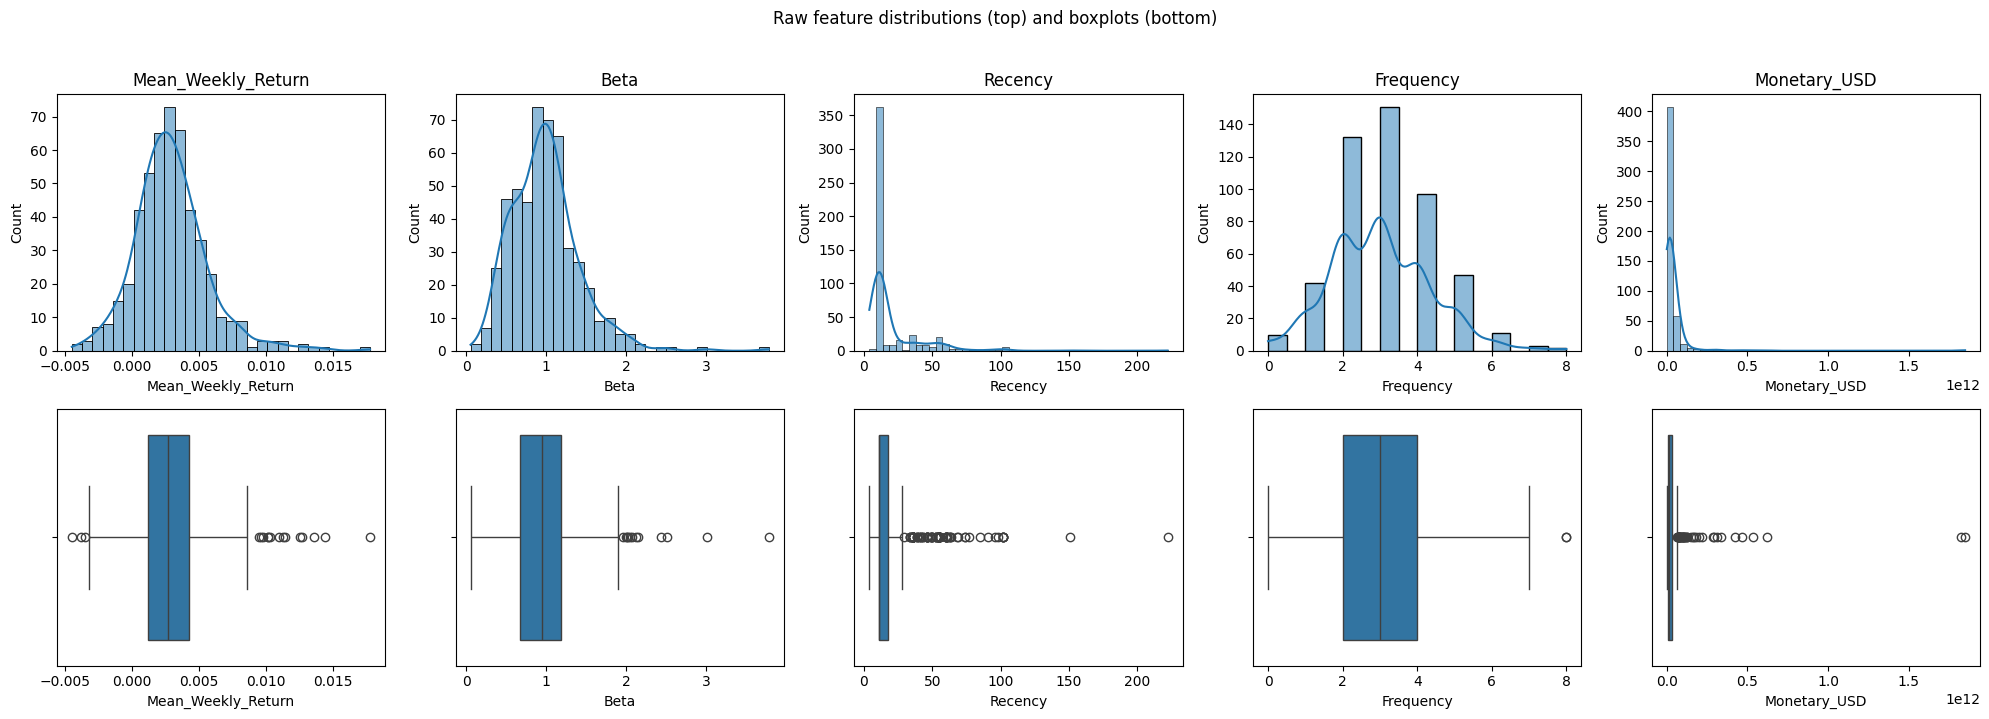

Skewness before / after a trial log1p:


,Skew raw,Skew after log1p
Recency,3.588,1.547
Frequency,0.410,-0.932
Monetary_USD,11.672,1.067


Skewness of the standardised model inputs:


,Mean_Weekly_Return,Beta,Recency,Frequency,Log1p_Monetary
Skewness,0.966,1.248,3.588,0.41,1.067


Means (~0) and std (~1):


,Mean_Weekly_Return,Beta,Recency,Frequency,Log1p_Monetary
mean,-0.000,0.000,-0.000,0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001


Four baseline solutions (k = 3):


,Matrix,Algorithm,k,Silhouette,Cluster sizes
0,Risk-return,Agglomerative,3,0.284,"[212, 188, 95]"
1,Risk-return,K means,3,0.319,"[207, 167, 121]"
2,Trading activity,Agglomerative,3,0.308,"[254, 147, 94]"
3,Trading activity,K means,3,0.325,"[275, 155, 65]"


In [27]:
display(risk_return_raw.head())
display(activity_raw.head())

def diagnostics(df):
    rows = []
    for c in df.columns:
        x = df[c]
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
        rows.append({"Feature": c, "Skewness": skew(x), "Min": x.min(), "Median": x.median(),
                     "Max": x.max(), "IQR outliers": n_out, "Outliers %": 100 * n_out / len(x)})
    return pd.DataFrame(rows).set_index("Feature").round(3)

all_raw = risk_return_raw.join(activity_raw)
print("Raw features:")
display(diagnostics(all_raw))

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, c in enumerate(all_raw.columns):
    sns.histplot(all_raw[c], kde=True, ax=axes[0, i]); axes[0, i].set_title(c)
    sns.boxplot(x=all_raw[c], ax=axes[1, i])
plt.suptitle("Raw feature distributions (top) and boxplots (bottom)", y=1.02)
plt.tight_layout(); plt.show()

# Trial log1p on R, F, M (diagnostic only; only M is transformed in the models)
cols3 = ["Recency", "Frequency", "Monetary_USD"]
trial = pd.DataFrame({"Skew raw": [skew(activity_raw[c]) for c in cols3],
                      "Skew after log1p": [skew(np.log1p(activity_raw[c])) for c in cols3]},
                     index=cols3).round(3)
print("Skewness before / after a trial log1p:")
display(trial)

# Apply log1p to M only
activity_t = activity_raw.copy()
activity_t["Log1p_Monetary"] = np.log1p(activity_t.pop("Monetary_USD"))
activity_t = activity_t[["Recency", "Frequency", "Log1p_Monetary"]]
risk_return_t = risk_return_raw.copy()

# Standardise each matrix separately
X_rr = pd.DataFrame(StandardScaler().fit_transform(risk_return_t), index=common_shares, columns=risk_return_t.columns)
X_act = pd.DataFrame(StandardScaler().fit_transform(activity_t), index=common_shares, columns=activity_t.columns)

print("Skewness of the standardised model inputs:")
display(pd.concat([X_rr, X_act], axis=1).apply(skew).round(3).to_frame("Skewness").T)
print("Means (~0) and std (~1):")
display(pd.concat([X_rr, X_act], axis=1).agg(["mean", "std"]).round(3))

RAW = {"Risk-return": risk_return_raw, "Trading activity": activity_raw}   # original units (profiles)
X = {"Risk-return": X_rr, "Trading activity": X_act}                        # standardised inputs (models)

# Four baseline solutions
baseline = pd.DataFrame(index=common_shares)
summary = []
for name in X:
    agg = AgglomerativeClustering(n_clusters=BASELINE_K, linkage="ward").fit_predict(X[name])
    km = KMeans(n_clusters=BASELINE_K, n_init=50, random_state=RANDOM_STATE).fit_predict(X[name])
    for algo, lab in [("Agglomerative", agg), ("K means", km)]:
        baseline[f"{name} | {algo}"] = lab
        summary.append({"Matrix": name, "Algorithm": algo, "k": BASELINE_K,
                        "Silhouette": round(silhouette_score(X[name], lab), 3),
                        "Cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True)})
print("Four baseline solutions (k = %d):" % BASELINE_K)
display(pd.DataFrame(summary))

## 2.2 Agglomerative clustering (Ward, Euclidean, standardised features)

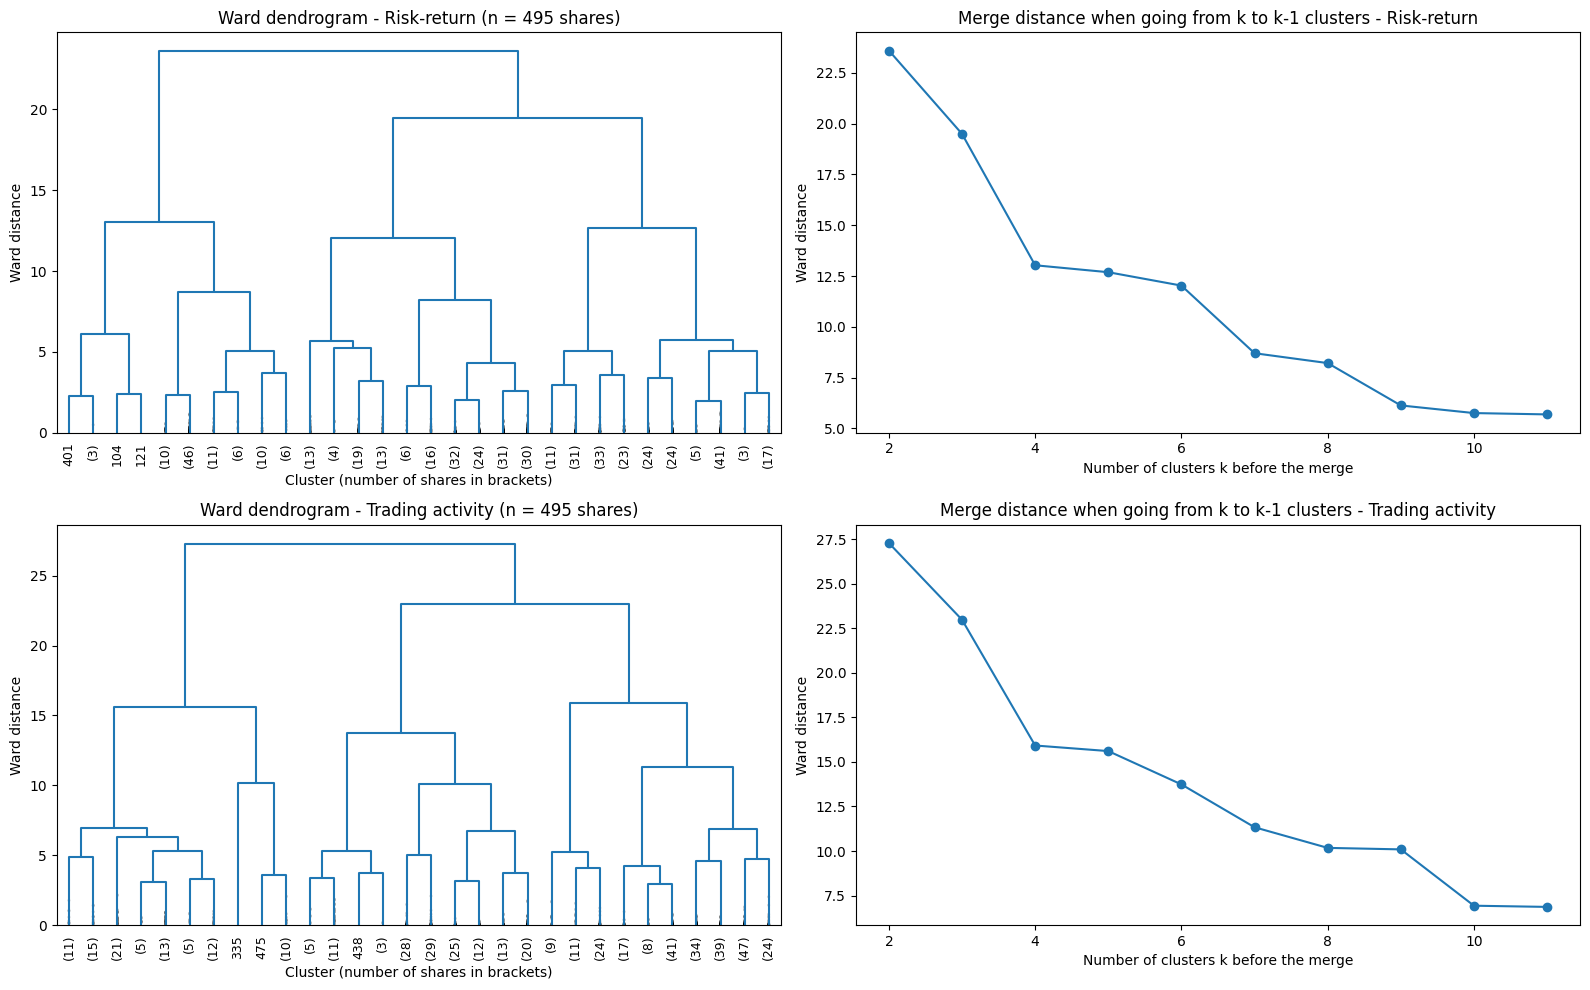


=== Agglomerative (Ward) - Risk-return ===


,Silhouette,Smallest cluster,Smallest cluster %,Largest cluster %,Sizes
k,,,,,
2,0.350,95,19.192,80.808,"[400, 95]"
3,0.284,95,19.192,42.828,"[212, 188, 95]"
4,0.291,6,1.212,42.828,"[212, 188, 89, 6]"
5,0.272,6,1.212,37.980,"[188, 114, 98, 89, 6]"
6,0.301,6,1.212,28.081,"[139, 114, 98, 89, 49, 6]"
7,0.296,6,1.212,28.081,"[139, 114, 98, 56, 49, 33, 6]"
8,0.313,6,1.212,23.636,"[117, 114, 98, 56, 49, 33, 22, 6]"



=== Agglomerative (Ward) - Trading activity ===


,Silhouette,Smallest cluster,Smallest cluster %,Largest cluster %,Sizes
k,,,,,
2,0.358,94,18.990,81.010,"[401, 94]"
3,0.308,94,18.990,51.313,"[254, 147, 94]"
4,0.292,44,8.889,42.424,"[210, 147, 94, 44]"
5,0.312,12,2.424,42.424,"[210, 147, 82, 44, 12]"
6,0.320,12,2.424,42.424,"[210, 127, 82, 44, 20, 12]"
7,0.299,12,2.424,29.091,"[144, 127, 82, 66, 44, 20, 12]"
8,0.301,1,0.202,29.091,"[144, 127, 82, 66, 44, 20, 11, 1]"


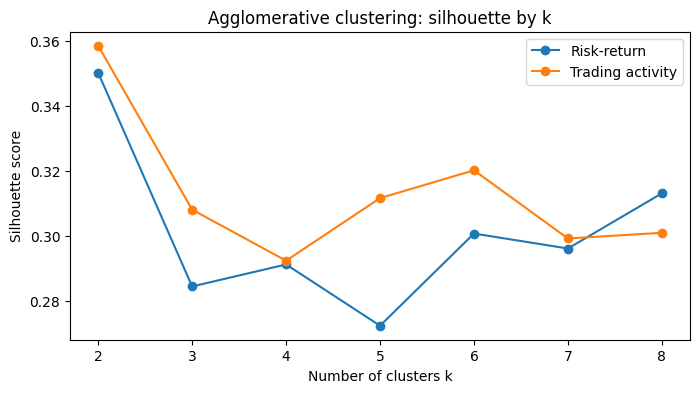


--- Agglomerative | Risk-return | k = 2 (silhouette 0.350) ---


,n shares,Mean_Weekly_Return,Beta
Cluster,,,
0,400,0.0021,0.9006
1,95,0.0065,1.3259



--- Agglomerative | Risk-return | k = 3 (silhouette 0.284) ---


,n shares,Mean_Weekly_Return,Beta
Cluster,,,
0,95,0.0065,1.3259
1,212,0.0025,0.6361
2,188,0.0016,1.1988



--- Agglomerative | Trading activity | k = 2 (silhouette 0.358) ---


,n shares,Recency,Frequency,Monetary_USD
Cluster,,,,
0,401,12.3217,3.2170,3.822427e+10
1,94,55.5319,2.0745,4.565006e+10



--- Agglomerative | Trading activity | k = 3 (silhouette 0.308) ---


,n shares,Recency,Frequency,Monetary_USD
Cluster,,,,
0,254,12.1024,3.3661,1.177070e+10
1,94,55.5319,2.0745,4.565006e+10
2,147,12.7007,2.9592,8.393315e+10



--- Agglomerative | Trading activity | k = 4 (silhouette 0.292) ---


,n shares,Recency,Frequency,Monetary_USD
Cluster,,,,
0,94,55.5319,2.0745,4.565006e+10
1,210,11.1381,2.9476,1.113269e+10
2,147,12.7007,2.9592,8.393315e+10
3,44,16.7045,5.3636,1.481576e+10


Risk-return: selected k = 2 (silhouette 0.350; sizes [400, 95]; best silhouette overall at k = 2)
Trading activity: selected k = 2 (silhouette 0.358; sizes [401, 94]; best silhouette overall at k = 2)


In [28]:
linkages = {name: linkage(X[name], method="ward", metric="euclidean") for name in X}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for i, (name, Z) in enumerate(linkages.items()):
    dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
               show_contracted=True, ax=axes[i, 0], color_threshold=0)
    axes[i, 0].set_title(f"Ward dendrogram - {name} (n = {len(X[name])} shares)")
    axes[i, 0].set_xlabel("Cluster (number of shares in brackets)")
    axes[i, 0].set_ylabel("Ward distance")
    last = Z[-10:, 2][::-1]       # merge heights, last merge (2 -> 1 cluster) first
    axes[i, 1].plot(range(2, 12), last, marker="o")
    axes[i, 1].set_title(f"Merge distance when going from k to k-1 clusters - {name}")
    axes[i, 1].set_xlabel("Number of clusters k before the merge")
    axes[i, 1].set_ylabel("Ward distance")
plt.tight_layout(); plt.show()

def evaluate_k(model_factory, Xdf, ks=K_RANGE, with_inertia=False):
    """Fit a model for each k and return a table plus the labels of each solution."""
    rows, labels = [], {}
    for k in ks:
        model = model_factory(k)
        lab = model.fit_predict(Xdf)
        labels[k] = lab
        sizes = np.bincount(lab)
        row = {"k": k, "Silhouette": silhouette_score(Xdf, lab),
               "Smallest cluster": int(sizes.min()), "Smallest cluster %": 100 * sizes.min() / len(lab),
               "Largest cluster %": 100 * sizes.max() / len(lab),
               "Sizes": sorted(sizes.tolist(), reverse=True)}
        if with_inertia:
            row["Inertia"] = model.inertia_
        rows.append(row)
    return pd.DataFrame(rows).set_index("k"), labels

def choose_k(table, min_share=MIN_CLUSTER_SHARE):
    """Highest silhouette among solutions with no tiny cluster; falls back to all k if none qualify."""
    ok = table[table["Smallest cluster %"] >= 100 * min_share]
    pool = ok if len(ok) else table
    return int(pool["Silhouette"].idxmax())

def profile(raw_df, labels):
    """Cluster profile in ORIGINAL units (means) plus cluster size."""
    out = raw_df.assign(Cluster=labels).groupby("Cluster").mean()
    out.insert(0, "n shares", pd.Series(labels).value_counts().sort_index().values)
    return out.round(4)

agg_tables, agg_labels = {}, {}
for name in X:
    agg_tables[name], agg_labels[name] = evaluate_k(
        lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"), X[name])
    print(f"\n=== Agglomerative (Ward) - {name} ===")
    display(agg_tables[name].round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for name, t in agg_tables.items():
    ax.plot(t.index, t["Silhouette"], marker="o", label=name)
ax.set_xlabel("Number of clusters k"); ax.set_ylabel("Silhouette score")
ax.set_title("Agglomerative clustering: silhouette by k"); ax.legend()
plt.show()

# Interpretable profiles (original units) for the three best-scoring candidate k per matrix
for name in X:
    t = agg_tables[name]
    eligible = t[t["Smallest cluster %"] >= 100 * MIN_CLUSTER_SHARE]
    candidates = (eligible if len(eligible) else t).sort_values("Silhouette", ascending=False).index[:3]
    for k in sorted(candidates):
        print(f"\n--- Agglomerative | {name} | k = {k} (silhouette {t.loc[k, 'Silhouette']:.3f}) ---")
        display(profile(RAW[name], agg_labels[name][k]))

AGG_K_OVERRIDE = {"Risk-return": None, "Trading activity": None}   # e.g. {"Risk-return": 4, "Trading activity": 3}

AGG_K = {}
for name in X:
    auto = choose_k(agg_tables[name])
    AGG_K[name] = AGG_K_OVERRIDE[name] or auto
    t = agg_tables[name]
    print(f"{name}: selected k = {AGG_K[name]} "
          f"(silhouette {t.loc[AGG_K[name], 'Silhouette']:.3f}; sizes {t.loc[AGG_K[name], 'Sizes']}; "
          f"best silhouette overall at k = {int(t['Silhouette'].idxmax())})")

## 2.3 K means clustering (seed 42, `n_init = 50`)


=== K means - Risk-return ===


,Silhouette,Smallest cluster,Smallest cluster %,Largest cluster %,Sizes,Inertia
k,,,,,,
2,0.390,146,29.495,70.505,"[349, 146]",631.092
3,0.319,121,24.444,41.818,"[207, 167, 121]",477.821
4,0.323,40,8.081,34.747,"[172, 160, 123, 40]",376.903
5,0.337,23,4.646,31.313,"[155, 133, 129, 55, 23]",315.453
6,0.337,7,1.414,32.525,"[161, 115, 114, 56, 42, 7]",263.429
7,0.332,7,1.414,28.889,"[143, 92, 87, 75, 50, 41, 7]",227.120
8,0.353,7,1.414,28.081,"[139, 81, 78, 76, 44, 40, 30, 7]",194.851



=== K means - Trading activity ===


,Silhouette,Smallest cluster,Smallest cluster %,Largest cluster %,Sizes,Inertia
k,,,,,,
2,0.419,72,14.545,85.455,"[423, 72]",1087.230
3,0.325,65,13.131,55.556,"[275, 155, 65]",813.713
4,0.341,61,12.323,43.434,"[215, 124, 95, 61]",620.930
5,0.358,11,2.222,40.606,"[201, 124, 89, 70, 11]",524.806
6,0.347,11,2.222,28.889,"[143, 121, 106, 72, 42, 11]",445.024
7,0.349,1,0.202,29.293,"[145, 121, 104, 71, 42, 11, 1]",393.871
8,0.348,1,0.202,28.687,"[142, 108, 81, 67, 66, 19, 11, 1]",350.372


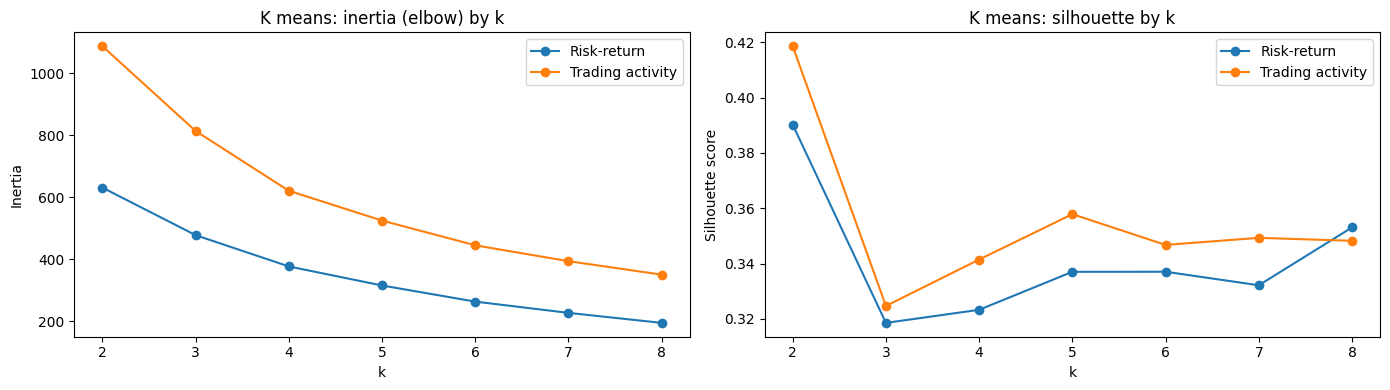


--- K means | Risk-return | k = 2 (silhouette 0.390) ---


,n shares,Mean_Weekly_Return,Beta
Cluster,,,
0,349,0.0019,0.8181
1,146,0.0055,1.3745



--- K means | Risk-return | k = 3 (silhouette 0.319) ---


,n shares,Mean_Weekly_Return,Beta
Cluster,,,
0,121,0.0061,1.3550
1,167,0.0010,1.1388
2,207,0.0026,0.6379



--- K means | Risk-return | k = 4 (silhouette 0.323) ---


,n shares,Mean_Weekly_Return,Beta
Cluster,,,
0,172,0.0045,0.9756
1,40,0.0078,1.7585
2,160,0.0016,0.5951
3,123,0.0009,1.2424


... (3 outputs left out)

,n shares,Recency,Frequency,Monetary_USD
Cluster,,,,
0,65,64.4769,1.6923,5.424750e+10
1,275,13.3600,3.3527,1.203905e+10
2,155,14.8129,2.9226,8.246587e+10



--- K means | Trading activity | k = 4 (silhouette 0.341) ---


,n shares,Recency,Frequency,Monetary_USD
Cluster,,,,
0,215,13.2791,2.3721,1.516509e+10
1,124,13.8952,4.5484,1.496389e+10
2,61,66.0492,1.6393,5.618444e+10
3,95,16.3579,3.2737,1.165870e+11



Risk-return: selected k = 2 (silhouette 0.390; inertia 631.1; sizes [349, 146])

Trading activity: selected k = 2 (silhouette 0.419; inertia 1087.2; sizes [423, 72])


In [29]:
km_tables, km_labels = {}, {}
for name in X:
    km_tables[name], km_labels[name] = evaluate_k(
        lambda k: KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE), X[name], with_inertia=True)
    print(f"\n=== K means - {name} ===")
    display(km_tables[name].round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, t in km_tables.items():
    axes[0].plot(t.index, t["Inertia"], marker="o", label=name)
    axes[1].plot(t.index, t["Silhouette"], marker="o", label=name)
axes[0].set_title("K means: inertia (elbow) by k"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].set_title("K means: silhouette by k"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette score")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

for name in X:
    t = km_tables[name]
    eligible = t[t["Smallest cluster %"] >= 100 * MIN_CLUSTER_SHARE]
    candidates = (eligible if len(eligible) else t).sort_values("Silhouette", ascending=False).index[:3]
    for k in sorted(candidates):
        print(f"\n--- K means | {name} | k = {k} (silhouette {t.loc[k, 'Silhouette']:.3f}) ---")
        display(profile(RAW[name], km_labels[name][k]))

KM_K_OVERRIDE = {"Risk-return": None, "Trading activity": None}
KM_K = {}
for name in X:
    KM_K[name] = KM_K_OVERRIDE[name] or choose_k(km_tables[name])
    t = km_tables[name]
    print(f"\n{name}: selected k = {KM_K[name]} (silhouette {t.loc[KM_K[name], 'Silhouette']:.3f}; "
          f"inertia {t.loc[KM_K[name], 'Inertia']:.1f}; sizes {t.loc[KM_K[name], 'Sizes']})")

## 2.4 Cluster profiles and algorithm comparison

Profiles are shown in original units (mean and median). For the risk-return matrix the plot uses the two raw features directly (no dimensionality reduction). For trading activity (3 features) a **PCA** on the standardised matrix gives the 2-D view; the loadings and explained variance are printed.


=== Agglomerative | Risk-return | k = 2 ===


,n shares,Mean_Weekly_Return,Beta,Mean_Weekly_Return (median),Beta (median)
Cluster,,,,,
0,400,0.0021,0.9006,0.0021,0.8850
1,95,0.0065,1.3259,0.0056,1.2209



=== K means | Risk-return | k = 2 ===


,n shares,Mean_Weekly_Return,Beta,Mean_Weekly_Return (median),Beta (median)
Cluster,,,,,
0,349,0.0019,0.8181,0.0020,0.8407
1,146,0.0055,1.3745,0.0049,1.2783



=== Agglomerative | Trading activity | k = 2 ===


,n shares,Recency,Frequency,Monetary_USD,Recency (median),Frequency (median),Monetary_USD (median)
Cluster,,,,,,,
0,401,12.3217,3.2170,"38,224,266,968.2561",11.0000,3.0000,"15,463,998,085.5800"
1,94,55.5319,2.0745,"45,650,062,907.3112",53.0000,2.0000,"20,950,199,883.7550"



=== K means | Trading activity | k = 2 ===


,n shares,Recency,Frequency,Monetary_USD,Recency (median),Frequency (median),Monetary_USD (median)
Cluster,,,,,,,
0,72,62.4861,1.8472,"80,600,576,037.0831",55.0000,2.0000,"23,084,451,234.0700"
1,423,13.3853,3.1962,"32,661,455,065.9290",11.0000,3.0000,"15,482,181,689.6800"


PCA (trading activity): PC1 = 45.7%, PC2 = 33.8%, total = 79.5%


,PC1 loading,PC2 loading
Recency,0.714,0.031
Frequency,-0.641,0.432
Log1p_Monetary,0.282,0.902


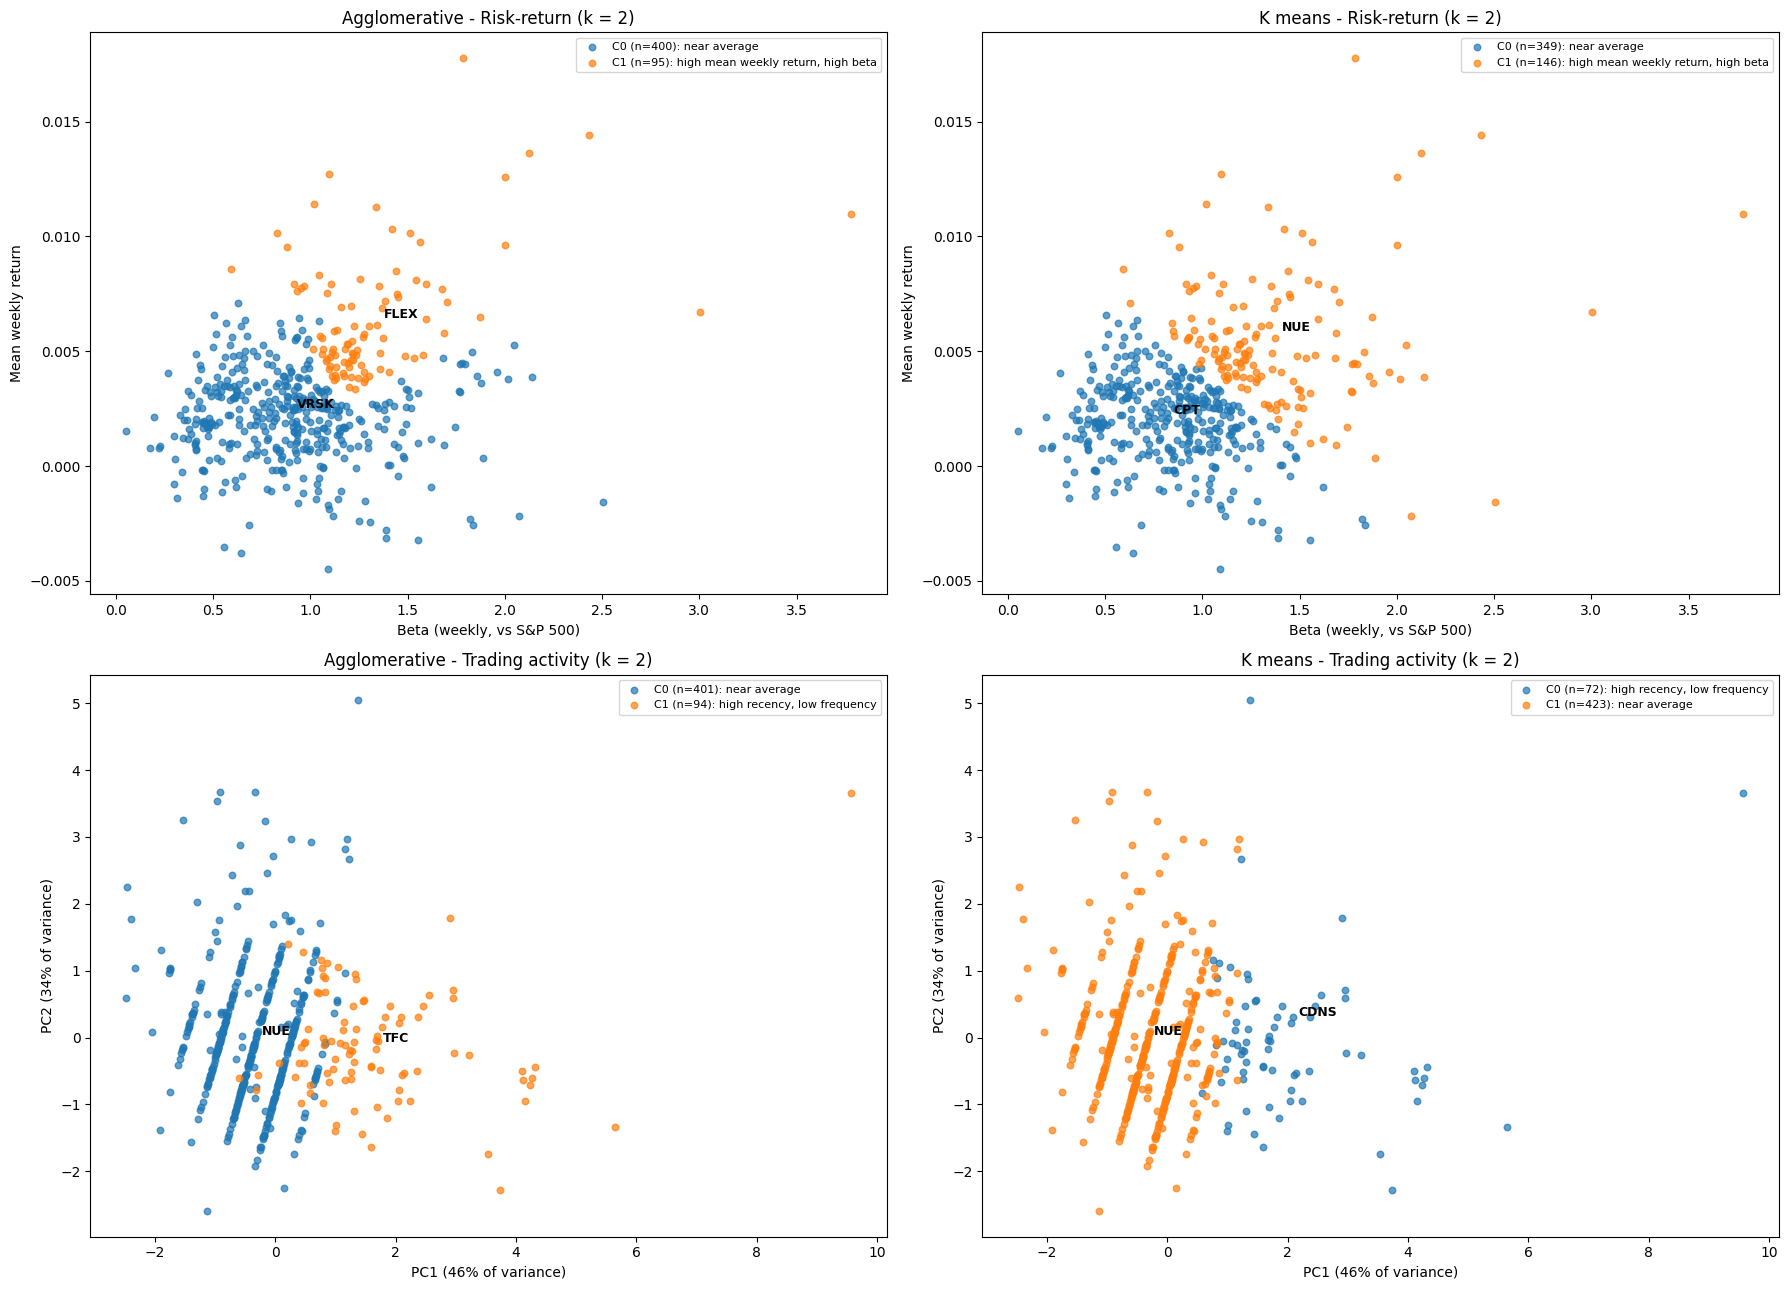

Matrix,Risk-return,Trading activity
Shares,495,495
Agglomerative k,2,2
Agglomerative silhouette,0.35,0.358
K means k,2,2
K means silhouette,0.39,0.419
ARI (own k),0.605,0.753
NMI (own k),0.544,0.625
K means silhouette (same k as agglo.),0.39,0.419
ARI (same k),0.605,0.753
Agglomerative sizes,"[400, 95]","[401, 94]"



Cross-tab - Risk-return (rows: agglomerative cluster, columns: K means cluster)


K means,0,1
Agglomerative,,
0,349,51
1,0,95



Cross-tab - Trading activity (rows: agglomerative cluster, columns: K means cluster)


K means,0,1
Agglomerative,,
0,2,399
1,70,24


In [30]:
final_labels = {}
for name in X:
    final_labels[(name, "Agglomerative")] = agg_labels[name][AGG_K[name]]
    final_labels[(name, "K means")] = km_labels[name][KM_K[name]]

pd.options.display.float_format = "{:,.4f}".format
for (name, algo), lab in final_labels.items():
    print(f"\n=== {algo} | {name} | k = {len(set(lab))} ===")
    means = profile(RAW[name], lab)
    medians = RAW[name].assign(Cluster=lab).groupby("Cluster").median().add_suffix(" (median)")
    display(pd.concat([means, medians], axis=1))
pd.reset_option("display.float_format")

def describe_clusters(Xdf, lab, thr=0.5):
    """Short automatic label per cluster from its mean standardised features."""
    z = Xdf.assign(Cluster=lab).groupby("Cluster").mean()
    names = {}
    for c, row in z.iterrows():
        parts = [("high " if v > 0 else "low ") + f.replace("Log1p_", "").replace("_", " ").lower()
                 for f, v in row.items() if abs(v) >= thr]
        names[c] = ", ".join(parts) if parts else "near average"
    return names

def centroid_share(Xdf, lab, cluster):
    pts = Xdf[lab == cluster]
    return (pts - pts.mean()).pow(2).sum(axis=1).idxmin()

coords = {}
coords["Risk-return"] = risk_return_raw[["Beta", "Mean_Weekly_Return"]].rename(columns={"Beta": "x", "Mean_Weekly_Return": "y"})
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_act)
coords["Trading activity"] = pd.DataFrame(pca.transform(X_act), index=common_shares, columns=["x", "y"])
print("PCA (trading activity): PC1 = %.1f%%, PC2 = %.1f%%, total = %.1f%%" % (
    100 * pca.explained_variance_ratio_[0], 100 * pca.explained_variance_ratio_[1], 100 * pca.explained_variance_ratio_.sum()))
display(pd.DataFrame(pca.components_.T, index=X_act.columns, columns=["PC1 loading", "PC2 loading"]).round(3))

axis_labels = {
    "Risk-return": ("Beta (weekly, vs S&P 500)", "Mean weekly return"),
    "Trading activity": ("PC1 (%.0f%% of variance)" % (100 * pca.explained_variance_ratio_[0]),
                         "PC2 (%.0f%% of variance)" % (100 * pca.explained_variance_ratio_[1])),
}

fig, axes = plt.subplots(2, 2, figsize=(18, 13))
palette = sns.color_palette("tab10")
for r, name in enumerate(X):
    for c, algo in enumerate(["Agglomerative", "K means"]):
        ax = axes[r, c]
        lab = final_labels[(name, algo)]
        names = describe_clusters(X[name], lab)
        for cl in sorted(set(lab)):
            m = lab == cl
            ax.scatter(coords[name].loc[m, "x"], coords[name].loc[m, "y"], s=22, alpha=0.7, color=palette[cl % 10],
                       label=f"C{cl} (n={m.sum()}): {names[cl]}")
            rep = centroid_share(X[name], lab, cl)
            ax.annotate(rep, (coords[name].loc[rep, "x"], coords[name].loc[rep, "y"]), fontsize=9, fontweight="bold",
                        xytext=(5, 5), textcoords="offset points")
        ax.set_xlabel(axis_labels[name][0]); ax.set_ylabel(axis_labels[name][1])
        ax.set_title(f"{algo} - {name} (k = {len(set(lab))})")
        ax.legend(fontsize=8, loc="best")
plt.tight_layout(); plt.show()

# Algorithm comparison on the same shares
rows = []
for name in X:
    a, k_ = final_labels[(name, "Agglomerative")], final_labels[(name, "K means")]
    k_same = KMeans(n_clusters=AGG_K[name], n_init=50, random_state=RANDOM_STATE).fit_predict(X[name])
    rows.append({
        "Matrix": name, "Shares": len(a),
        "Agglomerative k": AGG_K[name], "Agglomerative silhouette": silhouette_score(X[name], a),
        "K means k": KM_K[name], "K means silhouette": silhouette_score(X[name], k_),
        "ARI (own k)": adjusted_rand_score(a, k_), "NMI (own k)": normalized_mutual_info_score(a, k_),
        "K means silhouette (same k as agglo.)": silhouette_score(X[name], k_same),
        "ARI (same k)": adjusted_rand_score(a, k_same),
        "Agglomerative sizes": sorted(np.bincount(a).tolist(), reverse=True),
        "K means sizes": sorted(np.bincount(k_).tolist(), reverse=True),
    })
comparison = pd.DataFrame(rows).set_index("Matrix")
display(comparison.round(3).T)

for name in X:
    print(f"\nCross-tab - {name} (rows: agglomerative cluster, columns: K means cluster)")
    display(pd.crosstab(pd.Series(final_labels[(name, "Agglomerative")], index=common_shares, name="Agglomerative"),
                        pd.Series(final_labels[(name, "K means")], index=common_shares, name="K means")))

assignments = pd.DataFrame(index=common_shares)
for (name, algo), lab in final_labels.items():
    assignments[f"{name} | {algo}"] = lab
assignments.to_csv("sp500_cluster_assignments.csv")

## 2.5 RFM sensitivity and correlated inputs

### 2.5.1 Correlation analysis

Correlation among R, F and log1p(M). Standardisation gives every feature unit variance, but if some features are strongly correlated they share the same underlying information (e.g. "how active / liquid the share is"), so that dimension carries more weight in the Euclidean distance than an independent feature would. A high correlation alone does **not** prove that a feature dominates the clustering; the between-cluster variance share (η²) below checks what actually separates the clusters.

Pearson correlation (R, F, log1p(M)):


,Recency,Frequency,Log1p_Monetary
Recency,1.000,-0.341,0.164
Frequency,-0.341,1.000,0.019
Log1p_Monetary,0.164,0.019,1.000


Spearman correlation (R, F, log1p(M)):


,Recency,Frequency,Log1p_Monetary
Recency,1.000,-0.190,0.155
Frequency,-0.190,1.000,-0.042
Log1p_Monetary,0.155,-0.042,1.000


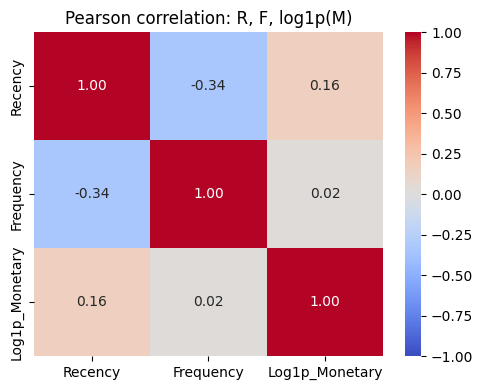

Explained variance ratio of the standardised R, F, log1p(M) matrix:


Component,PC1,PC2,PC3
Explained variance %,45.7,33.8,20.5


Between-cluster variance share (eta^2) per feature, selected Ward RFM solution (k = 2):


,Recency,Frequency,Log1p_Monetary
eta^2,0.634,0.114,0.004


In [31]:
corr_p = activity_t.corr(method="pearson")
corr_s = activity_t.corr(method="spearman")
print("Pearson correlation (R, F, log1p(M)):"); display(corr_p.round(3))
print("Spearman correlation (R, F, log1p(M)):"); display(corr_s.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr_p, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation: R, F, log1p(M)")
plt.tight_layout(); plt.show()

# How much of the standardised variance sits on one common dimension?
pca_all = PCA(random_state=RANDOM_STATE).fit(X_act)
print("Explained variance ratio of the standardised R, F, log1p(M) matrix:")
display(pd.DataFrame({"Component": [f"PC{i+1}" for i in range(3)],
                      "Explained variance %": (100 * pca_all.explained_variance_ratio_).round(1)}).set_index("Component").T)

def eta_squared(Xdf, lab):
    """Share of each (standardised) feature's variance that lies BETWEEN clusters."""
    out = {}
    for col in Xdf.columns:
        x = Xdf[col]
        grand = x.mean()
        ssb = sum(len(g) * (g.mean() - grand) ** 2 for _, g in x.groupby(np.asarray(lab)))
        out[col] = ssb / ((x - grand) ** 2).sum()
    return pd.Series(out, name="eta^2")

ref_labels = final_labels[("Trading activity", "Agglomerative")]
print(f"Between-cluster variance share (eta^2) per feature, selected Ward RFM solution (k = {AGG_K['Trading activity']}):")
display(eta_squared(X_act, ref_labels).round(3).to_frame().T)

### 2.5.2 Removal of Monetary

Selected Ward RFM solution repeated with **R and F only**: same shares, same selected k, matrix standardised afresh. Memberships are compared with the adjusted Rand index (invariant to cluster numbering). Traded value (M) is only a liquidity proxy; spread and price impact are not measured.

Selected k (same for both solutions): 2 | shares: 495
Adjusted Rand index (R,F,M vs R,F only): 0.953
Silhouette R,F,M: 0.358 | Silhouette R,F only: 0.518  (computed in different feature spaces, so not directly comparable)

Cross-tab (rows: R,F,M clusters; columns: R,F-only clusters):


"R,F only",0,1
"R,F,M",,
0,399,2
1,3,91



Profiles with R, F, M (original units):


,n shares,R mean,F mean,M mean (USD),M median (USD)
Full,,,,,
0,401,12.32,3.22,"38,224,266,968.26","15,463,998,085.58"
1,94,55.53,2.07,"45,650,062,907.31","20,950,199,883.76"


Profiles with R, F only (original units, traded value M NOT used for clustering):


,n shares,R mean,F mean,M mean (USD),M median (USD)
RF,,,,,
0,402,12.31,3.22,"37,699,912,620.71","15,395,754,458.17"
1,93,56.03,2.05,"47,996,474,129.39","21,052,589,467.38"


Share of log1p(M) variance explained by the clusters (eta^2):


,"R,F,M clusters","R,F-only clusters"
Log1p_Monetary,0.004,0.006


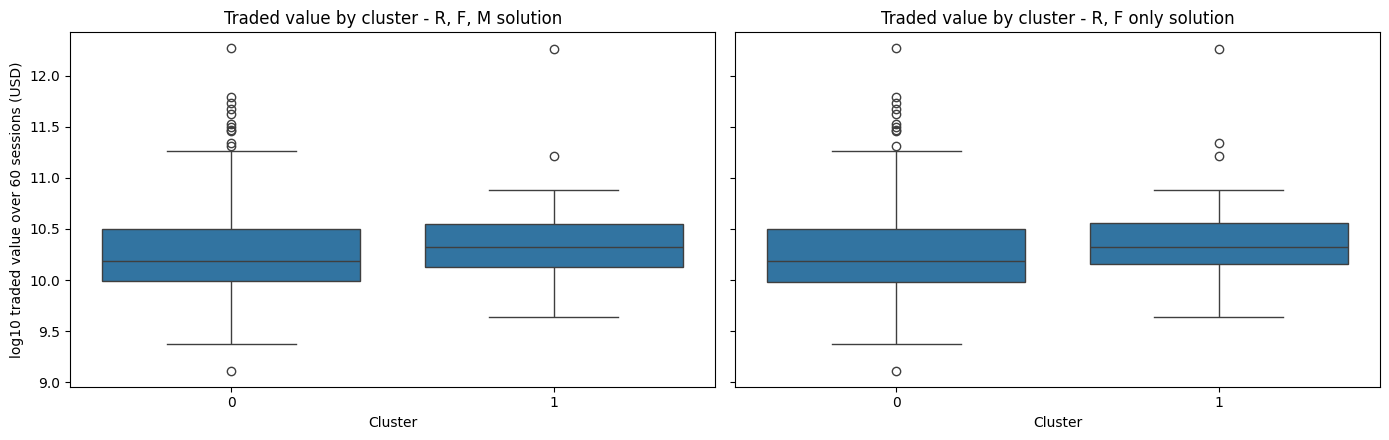

In [32]:
k_sel = AGG_K["Trading activity"]
X_rf = pd.DataFrame(StandardScaler().fit_transform(activity_t[["Recency", "Frequency"]]),
                    index=common_shares, columns=["Recency", "Frequency"])
rf_labels = AgglomerativeClustering(n_clusters=k_sel, linkage="ward").fit_predict(X_rf)

ari = adjusted_rand_score(ref_labels, rf_labels)
print(f"Selected k (same for both solutions): {k_sel} | shares: {len(common_shares)}")
print(f"Adjusted Rand index (R,F,M vs R,F only): {ari:.3f}")
print(f"Silhouette R,F,M: {silhouette_score(X_act, ref_labels):.3f} | Silhouette R,F only: {silhouette_score(X_rf, rf_labels):.3f}"
      "  (computed in different feature spaces, so not directly comparable)")

print("\nCross-tab (rows: R,F,M clusters; columns: R,F-only clusters):")
display(pd.crosstab(pd.Series(ref_labels, index=common_shares, name="R,F,M"),
                    pd.Series(rf_labels, index=common_shares, name="R,F only")))

cmp_df = activity_raw.assign(Full=ref_labels, RF=rf_labels)
def traded_value_profile(col):
    g = cmp_df.groupby(col)
    out = pd.DataFrame({
        "n shares": g.size(),
        "R mean": g["Recency"].mean(),
        "F mean": g["Frequency"].mean(),
        "M mean (USD)": g["Monetary_USD"].mean(),
        "M median (USD)": g["Monetary_USD"].median(),
    })
    return out

pd.options.display.float_format = "{:,.2f}".format
print("\nProfiles with R, F, M (original units):"); display(traded_value_profile("Full"))
print("Profiles with R, F only (original units, traded value M NOT used for clustering):"); display(traded_value_profile("RF"))
pd.reset_option("display.float_format")

# Does M still separate the R,F-only clusters? (eta^2 of log1p(M) under each partition)
eta_cmp = pd.DataFrame({
    "R,F,M clusters": eta_squared(activity_t[["Log1p_Monetary"]], ref_labels),
    "R,F-only clusters": eta_squared(activity_t[["Log1p_Monetary"]], rf_labels),
})
print("Share of log1p(M) variance explained by the clusters (eta^2):")
display(eta_cmp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (col, title) in zip(axes, [("Full", "R, F, M solution"), ("RF", "R, F only solution")]):
    sns.boxplot(x=cmp_df[col], y=np.log10(cmp_df["Monetary_USD"]), ax=ax)
    ax.set_title(f"Traded value by cluster - {title}")
    ax.set_xlabel("Cluster"); ax.set_ylabel("log10 traded value over 60 sessions (USD)")
plt.tight_layout(); plt.show()

pd.DataFrame({"R,F,M": ref_labels, "R,F only": rf_labels}, index=common_shares).to_csv("sp500_rfm_sensitivity_assignments.csv")

**Reading guide for the report.** ARI close to 1 → removing M barely changes the grouping (M adds little beyond R and F); a low ARI → M reshapes the clusters. If the R,F-only clusters still differ strongly in traded value (high η² of log1p(M)), M is mostly reproducing a liquidity/size level already linked to activity; if the full solution separates traded value much more than the R,F-only one, M is what introduces that liquidity split. Traded value is a liquidity proxy only (no spreads or price impact).

## 3.2.1 support – Sector composition and cross-comparison

Risk-return and RFM clusters are compared in original units and by GICS sector (today's classification, from Wikipedia).
**Lift** = sector share in the cluster ÷ sector share in the whole study set (1 = same as overall, >1 = over-represented).
Lift and Cramér's V are descriptive only, because some groups are small.

Sector composition of the study set:


,Shares,% of study set
Sector,,
Industrials,80,16.2
Financials,76,15.4
Information Technology,74,14.9
Health Care,59,11.9
Consumer Discretionary,47,9.5
Consumer Staples,32,6.5
Utilities,31,6.3
Real Estate,30,6.1
Materials,24,4.8


Association between sector and cluster (descriptive only):


,Matrix,Algorithm,k,Chi2,p-value,Cramer's V,Share of cells with expected count < 5
0,Risk-return,Agglomerative,2,46.1,0.0000,0.305,0.14
1,Risk-return,K means,2,100.0,0.0000,0.450,0.00
2,Trading activity,Agglomerative,2,22.7,0.0119,0.214,0.14
3,Trading activity,K means,2,23.9,0.0080,0.220,0.27


Dominant and most over-represented sector per cluster:


,Matrix,Algorithm,Cluster,n shares,Largest sector,% of cluster,Most over-represented sector,Lift
0,Risk-return,Agglomerative,0,400,Financials,15.5,Consumer Staples,1.24
1,Risk-return,Agglomerative,1,95,Information Technology,30.5,Information Technology,2.04
2,Risk-return,K means,0,349,Financials,16.3,Consumer Staples,1.37
3,Risk-return,K means,1,146,Information Technology,32.9,Information Technology,2.20
4,Trading activity,Agglomerative,0,401,Industrials,17.7,Real Estate,1.23
5,Trading activity,Agglomerative,1,94,Information Technology,21.3,Materials,1.76
6,Trading activity,K means,0,72,Information Technology,20.8,Utilities,2.22
7,Trading activity,K means,1,423,Industrials,17.7,Real Estate,1.17


... (12 outputs left out)


=== K means | Trading activity | sector counts per cluster ===


Cluster,0,1
Sector,,
Industrials,5,75
Financials,12,64
Information Technology,15,59
Health Care,8,51
Consumer Discretionary,8,39
Consumer Staples,5,27
Utilities,10,21
Real Estate,0,30
Materials,6,18


% of each cluster by sector:


Cluster,0,1
Sector,,
Industrials,6.9,17.7
Financials,16.7,15.1
Information Technology,20.8,13.9
Health Care,11.1,12.1
Consumer Discretionary,11.1,9.2
Consumer Staples,6.9,6.4
Utilities,13.9,5.0
Real Estate,0.0,7.1
Materials,8.3,4.3


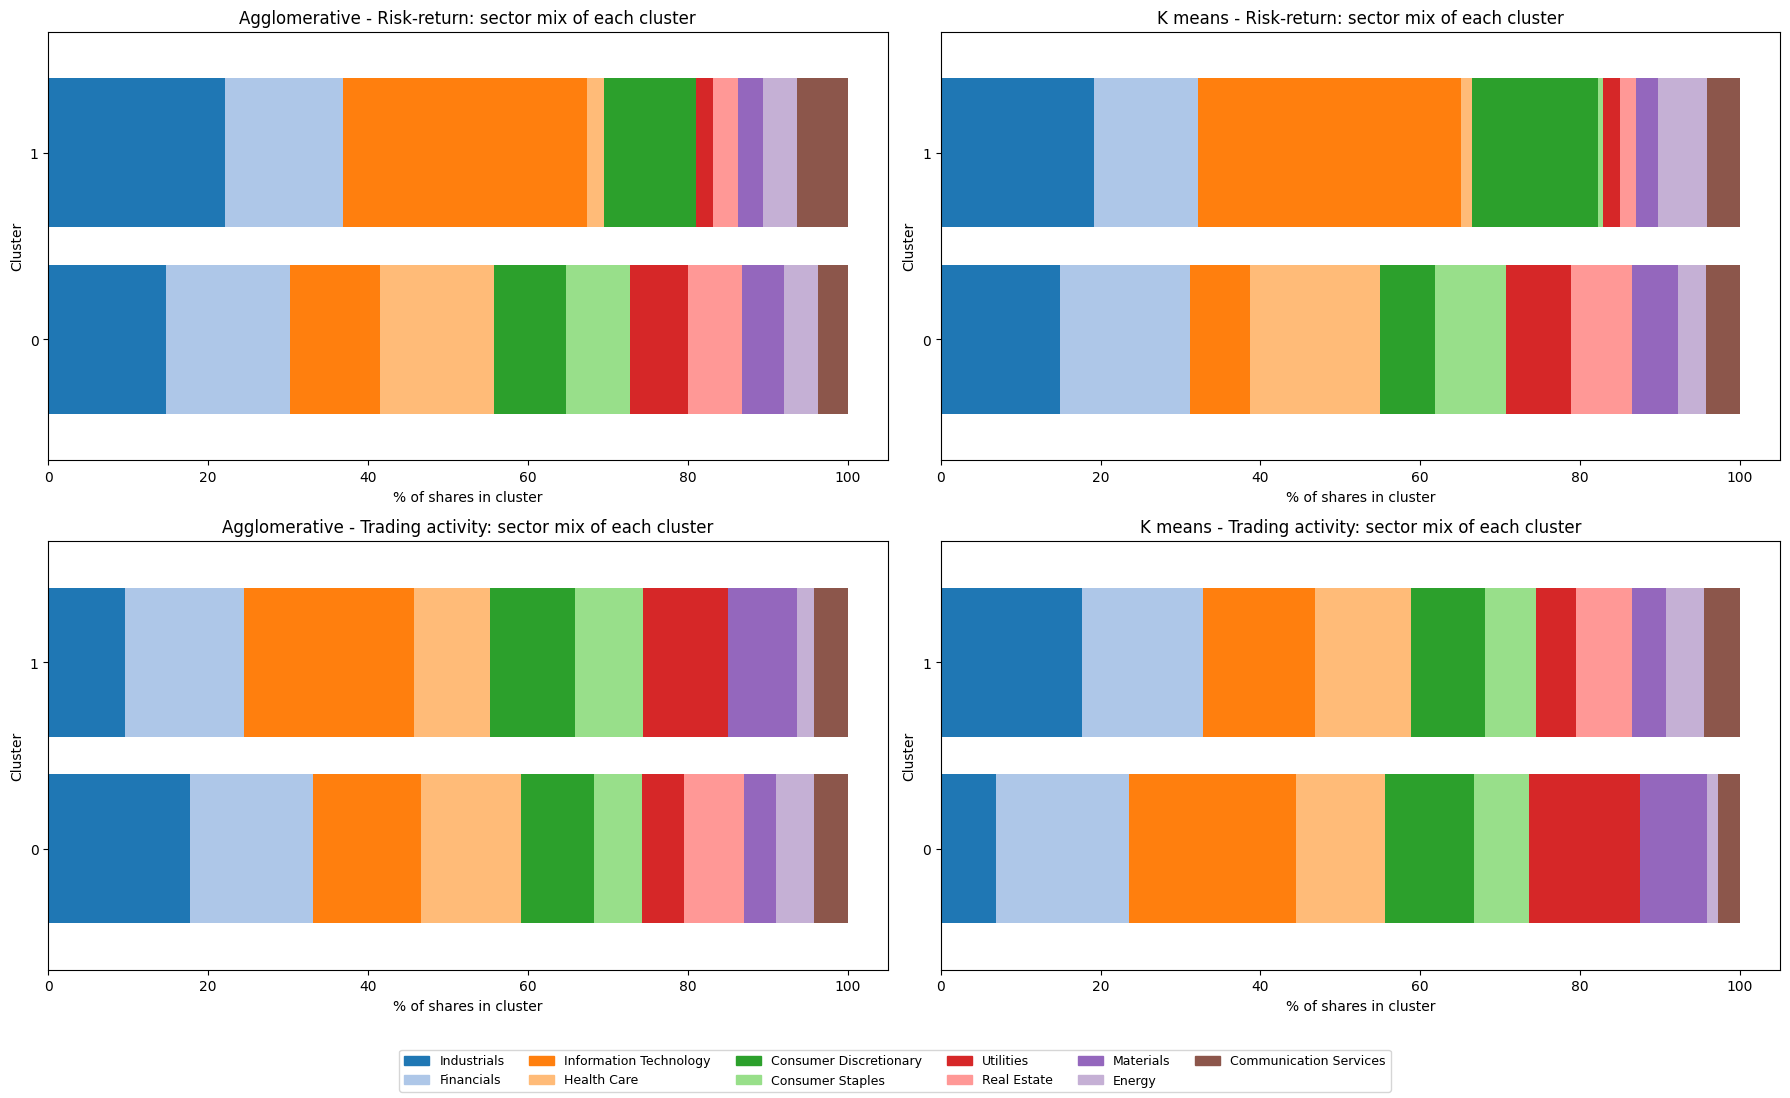

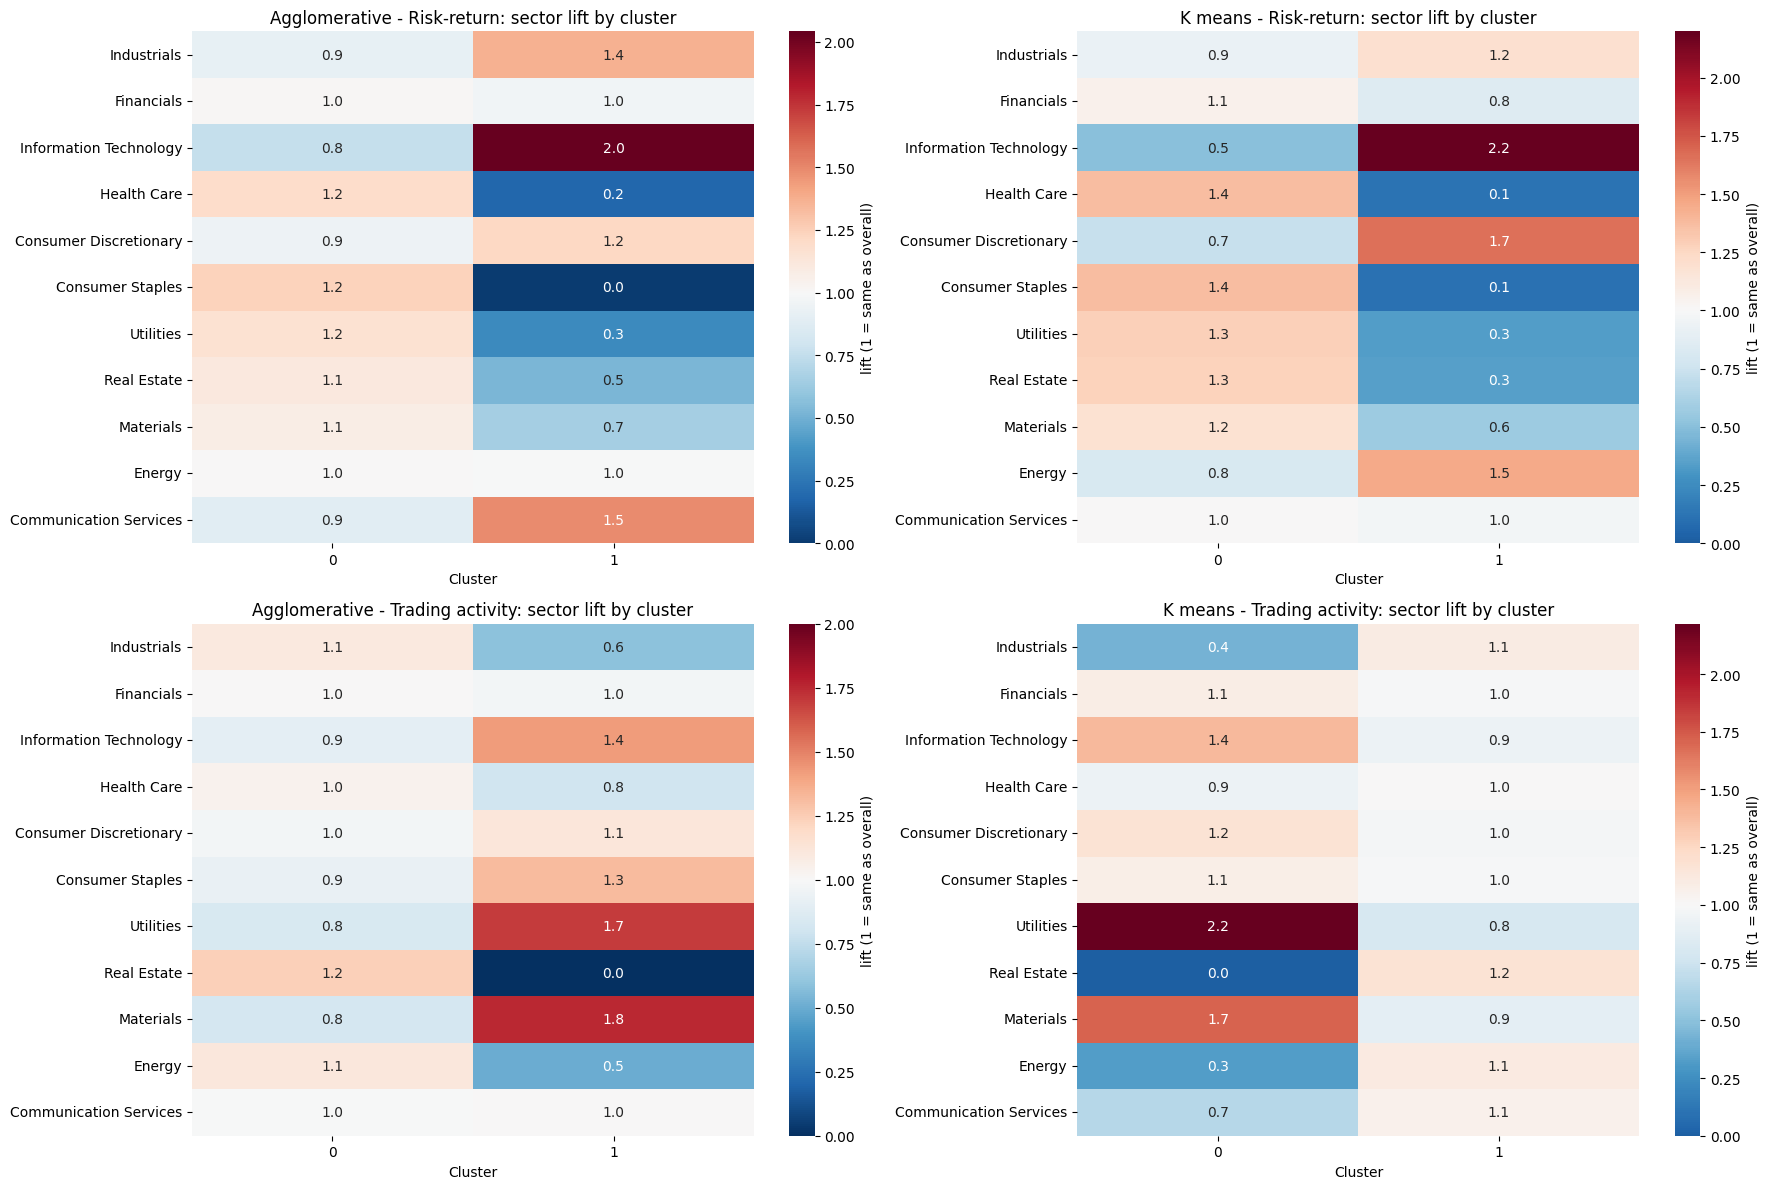

In [33]:
from scipy.stats import chi2_contingency
from matplotlib.patches import Patch

# ---- Sector for each share in the study ----
sector_map = (sp500_df.assign(Share=sp500_df["Symbol"].str.replace(".", "-", regex=False))
              .drop_duplicates("Share").set_index("Share")["GICS Sector"])
sectors = sector_map.reindex(common_shares).fillna("Unknown").rename("Sector")
sector_order = sectors.value_counts().index.tolist()
sector_colors = dict(zip(sector_order, sns.color_palette("tab20", len(sector_order))))

print("Sector composition of the study set:")
sector_overview = sectors.value_counts().to_frame("Shares")
sector_overview["% of study set"] = (100 * sector_overview["Shares"] / len(sectors)).round(1)
display(sector_overview)

def sector_tables(lab):
    """Counts, % of each cluster and lift (cluster share / overall share) by sector."""
    ct = pd.crosstab(sectors, pd.Series(lab, index=common_shares, name="Cluster")).reindex(sector_order)
    pct = 100 * ct / ct.sum()
    overall = 100 * sectors.value_counts(normalize=True).reindex(sector_order)
    lift = pct.div(overall, axis=0)
    return ct, pct, lift

def chi_cramer(ct):
    chi2, p, dof, exp = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return chi2, p, v, float((exp < 5).mean())

tabs, summ_rows, dom_rows = {}, [], []
for (name, algo), lab in final_labels.items():
    ct, pct, lift = sector_tables(lab)
    tabs[(name, algo)] = (ct, pct, lift)
    chi2, p, v, low_exp = chi_cramer(ct)
    summ_rows.append({"Matrix": name, "Algorithm": algo, "k": ct.shape[1], "Chi2": round(chi2, 1),
                      "p-value": round(p, 4), "Cramer's V": round(v, 3), "Share of cells with expected count < 5": round(low_exp, 2)})
    for cl in ct.columns:
        top = ct[cl].idxmax()
        dom_rows.append({"Matrix": name, "Algorithm": algo, "Cluster": cl, "n shares": int(ct[cl].sum()),
                         "Largest sector": top, "% of cluster": round(100 * ct.loc[top, cl] / ct[cl].sum(), 1),
                         "Most over-represented sector": lift[cl].idxmax(), "Lift": round(lift[cl].max(), 2)})

print("Association between sector and cluster (descriptive only):")
display(pd.DataFrame(summ_rows))
print("Dominant and most over-represented sector per cluster:")
display(pd.DataFrame(dom_rows))

for (name, algo), (ct, pct, lift) in tabs.items():
    print(f"\n=== {algo} | {name} | sector counts per cluster ===")
    display(ct)
    print("% of each cluster by sector:")
    display(pct.round(1))

# ---- Stacked bars: sector composition of each cluster ----
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for r, name in enumerate(X):
    for c, algo in enumerate(["Agglomerative", "K means"]):
        ct, pct, lift = tabs[(name, algo)]
        pct.T.plot(kind="barh", stacked=True, ax=axes[r, c], color=[sector_colors[s] for s in pct.index],
                   legend=False, width=0.8)
        axes[r, c].set_title(f"{algo} - {name}: sector mix of each cluster")
        axes[r, c].set_xlabel("% of shares in cluster"); axes[r, c].set_ylabel("Cluster")
fig.legend(handles=[Patch(color=sector_colors[s], label=s) for s in sector_order],
           loc="lower center", ncol=min(6, len(sector_order)), fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

# ---- Heatmaps of lift (over/under-representation) ----
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for r, name in enumerate(X):
    for c, algo in enumerate(["Agglomerative", "K means"]):
        ct, pct, lift = tabs[(name, algo)]
        sns.heatmap(lift, annot=True, fmt=".1f", cmap="RdBu_r", center=1, vmin=0, vmax=max(2, float(lift.max().max())),
                    cbar_kws={"label": "lift (1 = same as overall)"}, ax=axes[r, c])
        axes[r, c].set_title(f"{algo} - {name}: sector lift by cluster")
        axes[r, c].set_xlabel("Cluster"); axes[r, c].set_ylabel("")
plt.tight_layout(); plt.show()


=== Agglomerative: risk-return clusters vs RFM clusters ===
ARI = 0.021 | NMI = 0.001 | Cramer's V = 0.032  (different feature spaces: low values mean the two views group shares differently)


RFM cluster,0,1
Risk-return cluster,,
0,327,73
1,74,21


RFM features (original units, medians) by risk-return cluster:


,Recency,Frequency,Monetary_USD
RR_cluster,,,
0,11.0,3.0,1.528914e+10
1,11.0,3.0,2.522724e+10


Return / beta (original units, means) by RFM cluster:


,Mean_Weekly_Return,Beta
RFM_cluster,,
0,0.0029,0.9736
1,0.0031,1.0189


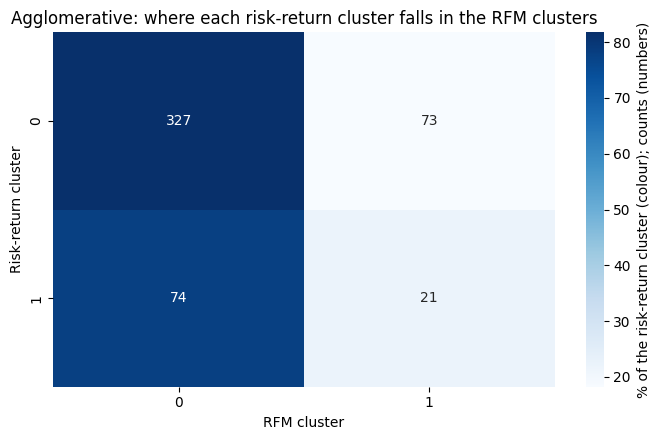


=== K means: risk-return clusters vs RFM clusters ===
ARI = 0.019 | NMI = 0.002 | Cramer's V = 0.041  (different feature spaces: low values mean the two views group shares differently)


RFM cluster,0,1
Risk-return cluster,,
0,47,302
1,25,121


RFM features (original units, medians) by risk-return cluster:


,Recency,Frequency,Monetary_USD
RR_cluster,,,
0,11.0,3.0,1.443833e+10
1,11.0,3.0,2.563639e+10


Return / beta (original units, means) by RFM cluster:


,Mean_Weekly_Return,Beta
RFM_cluster,,
0,0.0033,1.0267
1,0.0029,0.9746


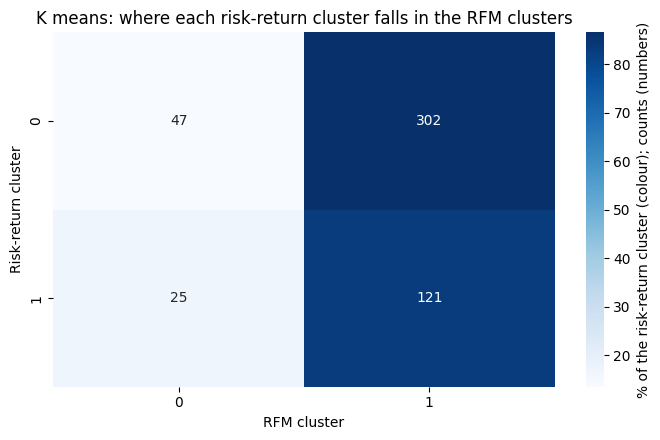

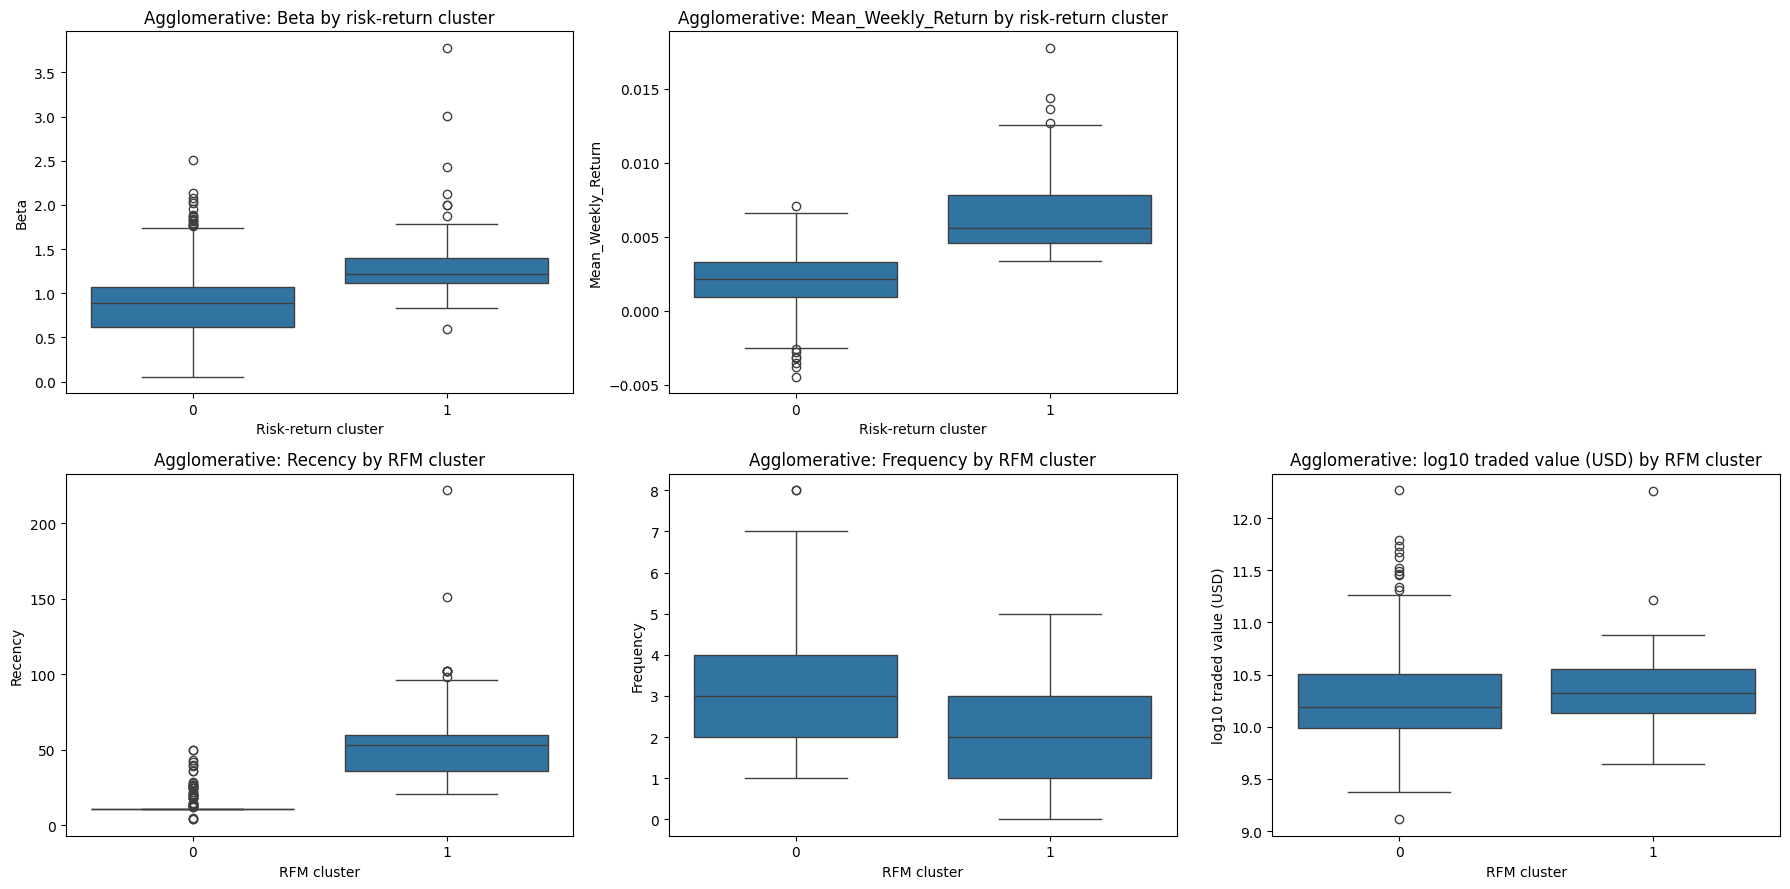

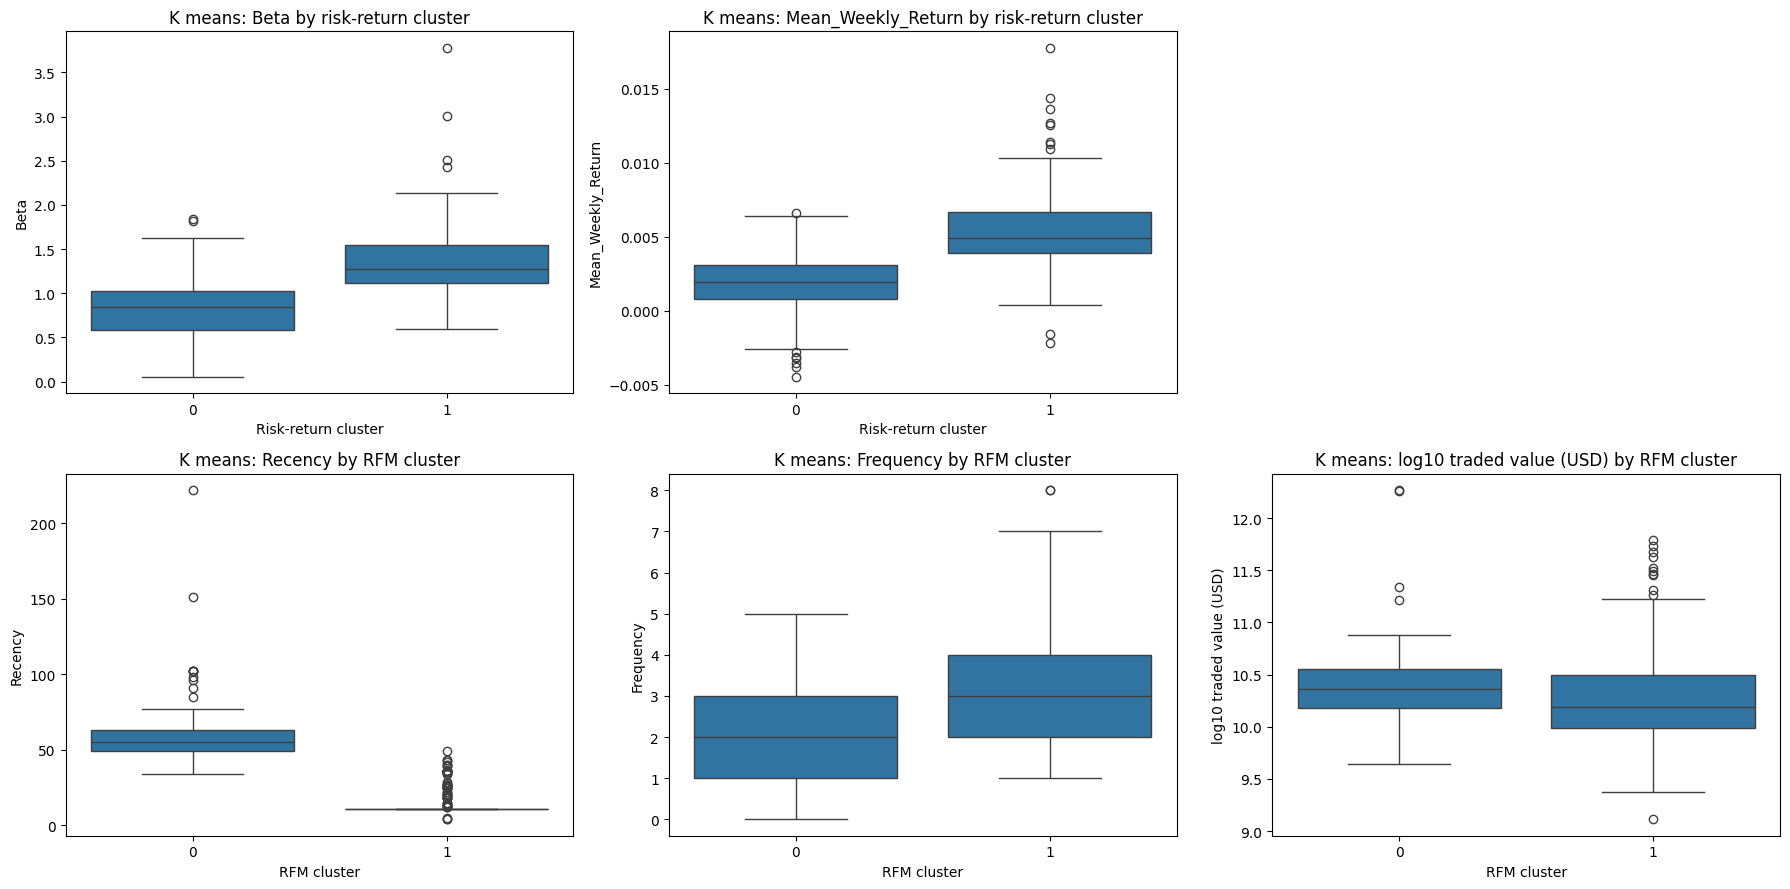

Saved sp500_cluster_assignments_with_sector.csv


In [34]:
# ---- Risk-return clusters vs RFM clusters (same shares) ----
combo_base = risk_return_raw.join(activity_raw)
for algo in ["Agglomerative", "K means"]:
    a = final_labels[("Risk-return", algo)]
    b = final_labels[("Trading activity", algo)]
    ct_x = pd.crosstab(pd.Series(a, index=common_shares, name="Risk-return cluster"),
                       pd.Series(b, index=common_shares, name="RFM cluster"))
    chi2, p, v, low = chi_cramer(ct_x)
    print(f"\n=== {algo}: risk-return clusters vs RFM clusters ===")
    print(f"ARI = {adjusted_rand_score(a, b):.3f} | NMI = {normalized_mutual_info_score(a, b):.3f} | Cramer's V = {v:.3f}"
          "  (different feature spaces: low values mean the two views group shares differently)")
    display(ct_x)

    combo = combo_base.assign(RR_cluster=a, RFM_cluster=b)
    print("RFM features (original units, medians) by risk-return cluster:")
    display(combo.groupby("RR_cluster")[["Recency", "Frequency", "Monetary_USD"]].median().round(2))
    print("Return / beta (original units, means) by RFM cluster:")
    display(combo.groupby("RFM_cluster")[["Mean_Weekly_Return", "Beta"]].mean().round(4))

    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.heatmap(100 * ct_x.div(ct_x.sum(axis=1), axis=0), annot=ct_x, fmt="d", cmap="Blues", ax=ax,
                cbar_kws={"label": "% of the risk-return cluster (colour); counts (numbers)"})
    ax.set_title(f"{algo}: where each risk-return cluster falls in the RFM clusters")
    plt.tight_layout(); plt.show()

# ---- Original-unit distributions by cluster ----
for algo in ["Agglomerative", "K means"]:
    a = final_labels[("Risk-return", algo)]
    b = final_labels[("Trading activity", algo)]
    plot_df = combo_base.assign(RR_cluster=a, RFM_cluster=b)
    plot_df["log10 traded value (USD)"] = np.log10(plot_df["Monetary_USD"])
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    for ax, col in zip(axes[0], ["Beta", "Mean_Weekly_Return"]):
        sns.boxplot(x="RR_cluster", y=col, data=plot_df, ax=ax)
        ax.set_title(f"{algo}: {col} by risk-return cluster"); ax.set_xlabel("Risk-return cluster")
    axes[0, 2].axis("off")
    for ax, col in zip(axes[1], ["Recency", "Frequency", "log10 traded value (USD)"]):
        sns.boxplot(x="RFM_cluster", y=col, data=plot_df, ax=ax)
        ax.set_title(f"{algo}: {col} by RFM cluster"); ax.set_xlabel("RFM cluster")
    plt.tight_layout(); plt.show()

# ---- Export assignments with sector ----
assign_sector = assignments.join(sectors)
assign_sector.to_csv("sp500_cluster_assignments_with_sector.csv")
print("Saved sp500_cluster_assignments_with_sector.csv")

In [35]:
# ---- Package versions, feature table and compressed data snapshot ----
import sys, sklearn, scipy, matplotlib

# 1) Package versions (Appendix A)
print("Python", sys.version.split()[0])
for m in [pd, np, sklearn, scipy, yf, matplotlib, sns]:
    print(m.__name__, m.__version__)

# 2) Feature table: one row per included share (Appendix B)
feature_table = (risk_return_raw
                 .join(beta_df[["Paired_weeks"]])
                 .join(activity_raw)
                 .assign(Log1p_Monetary=np.log1p(activity_raw["Monetary_USD"]))
                 .join(sectors)
                 .join(assignments)
                 .assign(RF_only_Ward=rf_labels,
                         Observation_Date=observation_date.date().isoformat()))
feature_table.index.name = "Share"
feature_table.to_csv("sp500_feature_table.csv")
print("Feature table:", feature_table.shape)
display(feature_table.head())

# 3) Compressed data snapshot (small enough for GitHub)
raw.to_pickle("sp500_yfinance_2021_2025.pkl.gz")
for f in ["sp500_yfinance_2021_2025.pkl", "sp500_yfinance_2021_2025.pkl.gz"]:
    print(f, round(os.path.getsize(f) / 1e6, 1), "MB")

Python 3.13.18
pandas 2.2.3
numpy 2.4.6
sklearn 1.6.1
scipy 1.16.3
yfinance 0.2.66
matplotlib 3.10.0
seaborn 0.13.2
Feature table: (495, 14)


,Mean_Weekly_Return,Beta,Paired_weeks,Recency,Frequency,Monetary_USD,Log1p_Monetary,Sector,Risk-return | Agglomerative,Risk-return | K means,Trading activity | Agglomerative,Trading activity | K means,RF_only_Ward,Observation_Date
Share,,,,,,,,,,,,,,
A,0.001121,1.074724,207,11.0,2.0,1.400180e+10,23.362451,Health Care,0,0,0,1,0,2024-12-31
AAPL,0.003930,1.174836,207,11.0,2.0,6.233034e+11,27.158299,Information Technology,1,1,0,1,0,2024-12-31
ABBV,0.003749,0.425366,207,11.0,3.0,6.837054e+10,24.948208,Health Care,0,0,0,1,0,2024-12-31
ABNB,0.001475,1.472709,207,11.0,3.0,3.652850e+10,24.321359,Consumer Discretionary,0,1,0,1,0,2024-12-31
ABT,0.000971,0.583543,207,11.0,1.0,3.523027e+10,24.285172,Health Care,0,0,0,1,0,2024-12-31


sp500_yfinance_2021_2025.pkl 32.4 MB
sp500_yfinance_2021_2025.pkl.gz 9.4 MB
